In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost lightgbm catboost shap

Note: you may need to restart the kernel to use updated packages.


In [2]:
# SETUP 2 — Library Verification

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import shap

print("===== LIBRARY CHECK =====")

print("Pandas       :", pd.__version__)
print("NumPy        :", np.__version__)
print("Scikit-learn :", sklearn.__version__)
print("XGBoost      :", XGBClassifier.__module__)
print("LightGBM     :", LGBMClassifier.__module__)
print("CatBoost     :", CatBoostClassifier.__module__)
print("SHAP         :", shap.__version__)

print("\n✓ All required libraries imported successfully!")

===== LIBRARY CHECK =====
Pandas       : 2.3.3
NumPy        : 2.3.5
Scikit-learn : 1.7.2
XGBoost      : xgboost.sklearn
LightGBM     : lightgbm.sklearn
CatBoost     : catboost.core
SHAP         : 0.52.0

✓ All required libraries imported successfully!


In [3]:
# STEP 1 — Load Dataset

import pandas as pd

# Load the dataset
df = pd.read_csv("flood.csv")

print("===== DATASET LOADED =====")
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

===== DATASET LOADED =====
Rows    : 50000
Columns : 21

First 5 rows:


,MonsoonIntensity,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,Encroachments,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
0,3,8,6,6,4,4,6,2,3,2,...,10,7,4,2,3,4,3,2,6,0.450
1,8,4,5,7,7,9,1,5,5,4,...,9,2,6,2,1,1,9,1,3,0.475
2,3,10,4,1,7,5,4,7,4,9,...,7,4,4,8,6,1,8,3,6,0.515
3,4,4,2,7,3,4,1,4,6,4,...,4,2,6,6,8,8,6,6,10,0.520
4,3,7,5,2,5,8,5,2,7,5,...,7,6,5,3,3,4,4,3,4,0.475



Column names:
['MonsoonIntensity', 'TopographyDrainage', 'RiverManagement', 'Deforestation', 'Urbanization', 'ClimateChange', 'DamsQuality', 'Siltation', 'AgriculturalPractices', 'Encroachments', 'IneffectiveDisasterPreparedness', 'DrainageSystems', 'CoastalVulnerability', 'Landslides', 'Watersheds', 'DeterioratingInfrastructure', 'PopulationScore', 'WetlandLoss', 'InadequatePlanning', 'PoliticalFactors', 'FloodProbability']


In [4]:
# STEP 2 — Missing Value Check

print("===== MISSING VALUE CHECK =====")

missing = df.isnull().sum()

display(
    missing.to_frame("Missing Values")
)

print("\nTotal missing values:", missing.sum())

===== MISSING VALUE CHECK =====


,Missing Values
MonsoonIntensity,0
TopographyDrainage,0
RiverManagement,0
Deforestation,0
Urbanization,0
ClimateChange,0
DamsQuality,0
Siltation,0
AgriculturalPractices,0
Encroachments,0



Total missing values: 0


In [5]:
# STEP 3 — Duplicate Check

print("===== DUPLICATE ROW CHECK =====")

duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

if duplicate_count == 0:
    print("✓ No duplicate rows found.")
else:
    print("⚠ Duplicate rows found.")

===== DUPLICATE ROW CHECK =====
Duplicate rows: 0
✓ No duplicate rows found.


In [6]:
# STEP 4 — Data Type Check

print("===== DATA TYPES =====")

display(
    df.dtypes.to_frame("Data Type")
)

print("\nNumber of columns by data type:")
print(df.dtypes.value_counts())

===== DATA TYPES =====


,Data Type
MonsoonIntensity,int64
TopographyDrainage,int64
RiverManagement,int64
Deforestation,int64
Urbanization,int64
ClimateChange,int64
DamsQuality,int64
Siltation,int64
AgriculturalPractices,int64
Encroachments,int64



Number of columns by data type:
int64      20
float64     1
Name: count, dtype: int64


In [7]:
# STEP 5 — Create Flood Occurrence Target

df["FloodOccurrence"] = (
    df["FloodProbability"] >= 0.50
).astype(int)

print("===== TARGET CREATED =====")

print("Target column:", "FloodOccurrence")

print("\nClass distribution:")

target_counts = (
    df["FloodOccurrence"]
    .value_counts()
    .sort_index()
)

print("No Flood (0):", target_counts.get(0, 0))
print("Flood (1)   :", target_counts.get(1, 0))

print("\nClass percentages:")

target_percent = (
    df["FloodOccurrence"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("No Flood (0):", round(target_percent.get(0, 0), 2), "%")
print("Flood (1)   :", round(target_percent.get(1, 0), 2), "%")

===== TARGET CREATED =====
Target column: FloodOccurrence

Class distribution:
No Flood (0): 24487
Flood (1)   : 25513

Class percentages:
No Flood (0): 48.97 %
Flood (1)   : 51.03 %


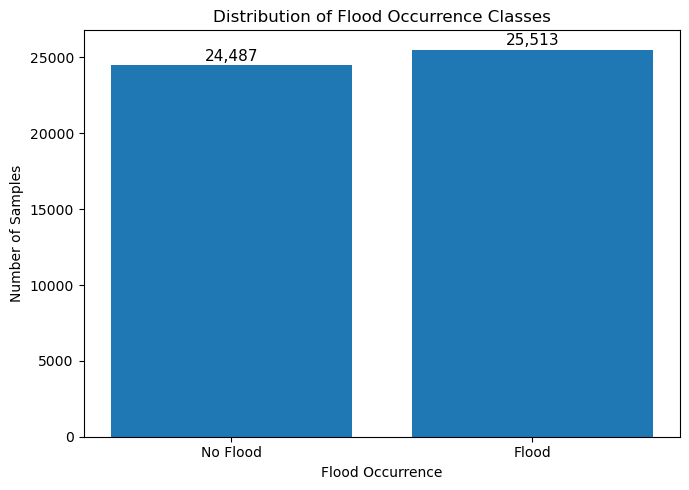

In [8]:
# STEP 6 — Target Distribution Graph

import matplotlib.pyplot as plt

counts = df["FloodOccurrence"].value_counts().sort_index()

labels = ["No Flood", "Flood"]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    labels,
    counts.values
)

plt.title("Distribution of Flood Occurrence Classes")
plt.xlabel("Flood Occurrence")
plt.ylabel("Number of Samples")

# Add values above bars
for bar, value in zip(bars, counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 300,
        f"{value:,}",
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()

In [9]:
# STEP 7 — Separate Features and Target

feature_columns = [
    "MonsoonIntensity",
    "TopographyDrainage",
    "RiverManagement",
    "Deforestation",
    "Urbanization",
    "ClimateChange",
    "DamsQuality",
    "Siltation",
    "AgriculturalPractices",
    "Encroachments",
    "IneffectiveDisasterPreparedness",
    "DrainageSystems",
    "CoastalVulnerability",
    "Landslides",
    "Watersheds",
    "DeterioratingInfrastructure",
    "PopulationScore",
    "WetlandLoss",
    "InadequatePlanning",
    "PoliticalFactors"
]

# Input features
X = df[feature_columns]

# Target
y = df["FloodOccurrence"]

print("===== FEATURE-TARGET SEPARATION =====")

print("Number of input features:", X.shape[1])
print("Number of samples:", X.shape[0])

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget:", y.name)

print("\nFloodProbability in X:",
      "FloodProbability" in X.columns)

print("FloodOccurrence in X:",
      "FloodOccurrence" in X.columns)

print("\n✓ Feature-target separation completed.")

===== FEATURE-TARGET SEPARATION =====
Number of input features: 20
Number of samples: 50000

X shape: (50000, 20)
y shape: (50000,)

Target: FloodOccurrence

FloodProbability in X: False
FloodOccurrence in X: False

✓ Feature-target separation completed.


In [10]:
# STEP 8 — Basic Feature Statistics

print("===== BASIC FEATURE STATISTICS =====")

feature_stats = X.describe().T

display(feature_stats)

===== BASIC FEATURE STATISTICS =====


,count,mean,std,min,25%,50%,75%,max
MonsoonIntensity,50000.0,4.99148,2.236834,0.0,3.0,5.0,6.0,16.0
TopographyDrainage,50000.0,4.98410,2.246488,0.0,3.0,5.0,6.0,18.0
RiverManagement,50000.0,5.01594,2.231310,0.0,3.0,5.0,6.0,16.0
Deforestation,50000.0,5.00848,2.222743,0.0,3.0,5.0,6.0,17.0
Urbanization,50000.0,4.98906,2.243159,0.0,3.0,5.0,6.0,17.0
ClimateChange,50000.0,4.98834,2.226761,0.0,3.0,5.0,6.0,17.0
DamsQuality,50000.0,5.01536,2.245000,0.0,3.0,5.0,6.0,16.0
Siltation,50000.0,4.98860,2.232642,0.0,3.0,5.0,6.0,16.0
AgriculturalPractices,50000.0,5.00612,2.234588,0.0,3.0,5.0,6.0,16.0
Encroachments,50000.0,5.00638,2.241633,0.0,3.0,5.0,6.0,18.0


===== CORRELATION WITH FLOOD OCCURRENCE =====


,Correlation
Watersheds,0.188213
IneffectiveDisasterPreparedness,0.186179
TopographyDrainage,0.184892
Siltation,0.184071
DeterioratingInfrastructure,0.182531
DamsQuality,0.181387
PopulationScore,0.180307
MonsoonIntensity,0.178584
RiverManagement,0.178559
PoliticalFactors,0.178250


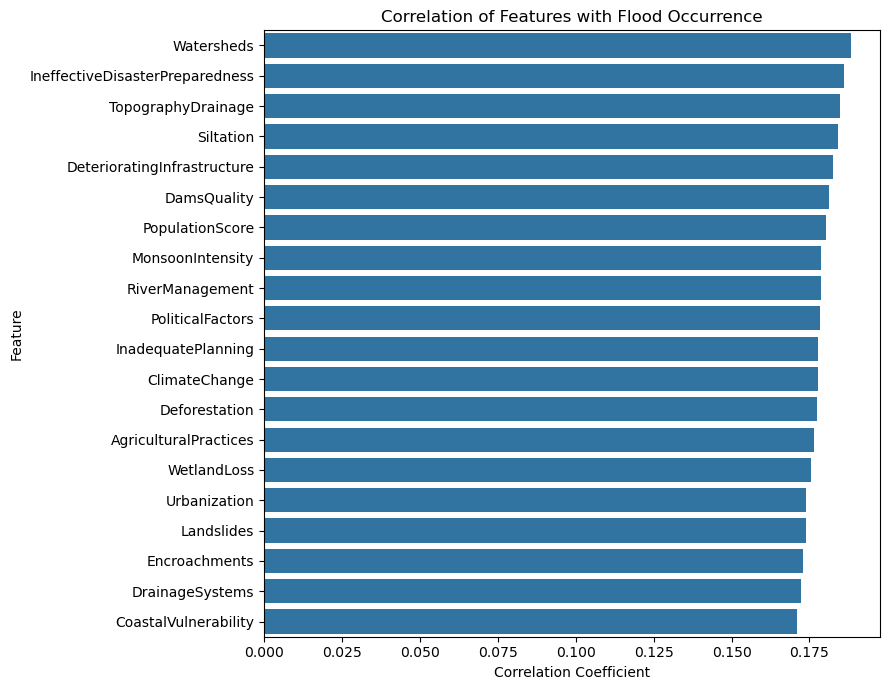

In [11]:
# STEP 9 — Feature Correlation Analysis

import matplotlib.pyplot as plt
import seaborn as sns

# Combine features and target
corr_data = X.copy()
corr_data["FloodOccurrence"] = y

# Calculate correlation with target
target_corr = (
    corr_data.corr()["FloodOccurrence"]
    .drop("FloodOccurrence")
    .sort_values(ascending=False)
)

print("===== CORRELATION WITH FLOOD OCCURRENCE =====")

display(
    target_corr.to_frame("Correlation")
)

# Plot
plt.figure(figsize=(9, 7))

sns.barplot(
    x=target_corr.values,
    y=target_corr.index
)

plt.title("Correlation of Features with Flood Occurrence")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

===== MULTICOLLINEARITY CHECK =====
No highly correlated feature pairs found (|r| >= 0.80).


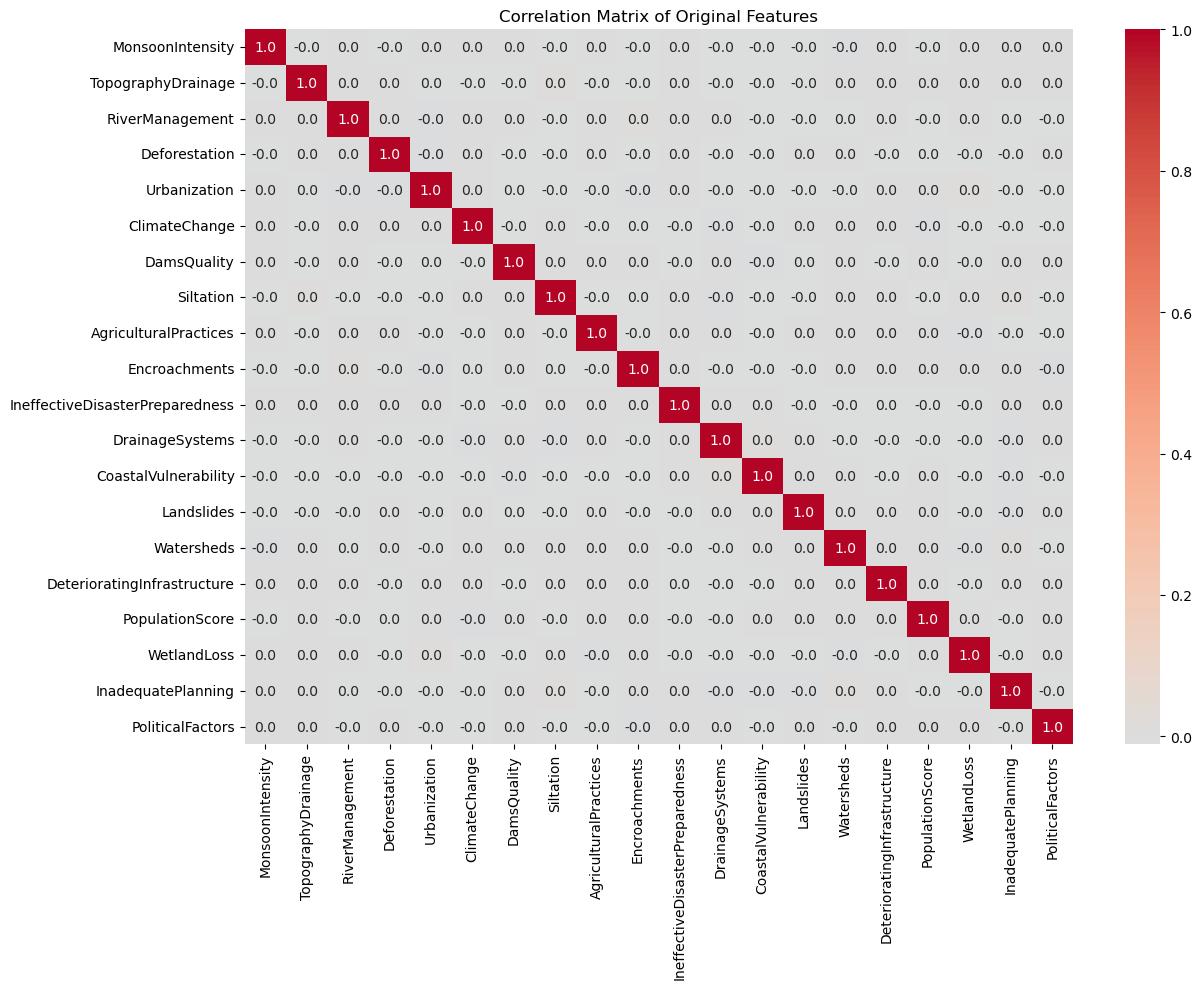

In [12]:
# STEP 10 — Multicollinearity Check

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation matrix of input features
feature_corr = X.corr()

# Find highly correlated pairs
high_corr_pairs = []

for i in range(len(feature_corr.columns)):
    for j in range(i + 1, len(feature_corr.columns)):
        
        corr_value = feature_corr.iloc[i, j]
        
        if abs(corr_value) >= 0.80:
            high_corr_pairs.append([
                feature_corr.columns[i],
                feature_corr.columns[j],
                corr_value
            ])

high_corr_df = pd.DataFrame(
    high_corr_pairs,
    columns=["Feature 1", "Feature 2", "Correlation"]
)

print("===== MULTICOLLINEARITY CHECK =====")

if high_corr_df.empty:
    print("No highly correlated feature pairs found (|r| >= 0.80).")
else:
    print("Highly correlated feature pairs:")
    display(high_corr_df)

# Heatmap
plt.figure(figsize=(13, 10))

sns.heatmap(
    feature_corr,
    annot=True,
    fmt=".1f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Original Features")
plt.tight_layout()
plt.show()

In [13]:
# STEP 11 — Domain-Based Feature Engineering

# 1. Meteorological Risk
df["Meteorological_Risk"] = (
    df["MonsoonIntensity"] +
    df["ClimateChange"]
) / 2

# 2. Hydrological & Infrastructure Risk
df["Hydrological_Infrastructure_Risk"] = (
    df["TopographyDrainage"] +
    df["RiverManagement"] +
    df["DamsQuality"] +
    df["DrainageSystems"] +
    df["DeterioratingInfrastructure"]
) / 5

# 3. Environmental Risk
df["Environmental_Risk"] = (
    df["Deforestation"] +
    df["Siltation"] +
    df["WetlandLoss"]
) / 3

# 4. Land-Use Risk
df["LandUse_Risk"] = (
    df["Urbanization"] +
    df["AgriculturalPractices"] +
    df["Encroachments"]
) / 3

# 5. Disaster Management Risk
df["DisasterManagement_Risk"] = (
    df["IneffectiveDisasterPreparedness"] +
    df["InadequatePlanning"]
) / 2

# 6. Natural Hazard Risk
df["NaturalHazard_Risk"] = (
    df["CoastalVulnerability"] +
    df["Landslides"] +
    df["Watersheds"]
) / 3

# 7. Socioeconomic Risk
df["Socioeconomic_Risk"] = (
    df["PopulationScore"] +
    df["PoliticalFactors"]
) / 2


domain_features = [
    "Meteorological_Risk",
    "Hydrological_Infrastructure_Risk",
    "Environmental_Risk",
    "LandUse_Risk",
    "DisasterManagement_Risk",
    "NaturalHazard_Risk",
    "Socioeconomic_Risk"
]

print("===== DOMAIN FEATURES CREATED =====")

for i, feature in enumerate(domain_features, 1):
    print(f"{i}. {feature}")

print("\nTotal domain features:", len(domain_features))

print("\nSample values:")
display(df[domain_features].head())

===== DOMAIN FEATURES CREATED =====
1. Meteorological_Risk
2. Hydrological_Infrastructure_Risk
3. Environmental_Risk
4. LandUse_Risk
5. DisasterManagement_Risk
6. NaturalHazard_Risk
7. Socioeconomic_Risk

Total domain features: 7

Sample values:


,Meteorological_Risk,Hydrological_Infrastructure_Risk,Environmental_Risk,LandUse_Risk,DisasterManagement_Risk,NaturalHazard_Risk,Socioeconomic_Risk
0,3.5,6.6,3.666667,3.000000,3.5,4.333333,5.0
1,8.5,4.0,7.000000,5.333333,3.5,3.333333,2.0
2,4.0,6.2,5.333333,6.666667,2.5,5.333333,3.5
3,4.0,3.8,5.666667,4.333333,7.5,4.666667,9.0
4,5.5,5.4,2.666667,5.666667,5.0,4.666667,4.0


In [14]:
# STEP 12 — Interaction Feature Engineering

# 1. Monsoon × Drainage
df["Monsoon_Drainage_Interaction"] = (
    df["MonsoonIntensity"] * df["DrainageSystems"]
)

# 2. Urbanization × Drainage
df["Urbanization_Drainage_Interaction"] = (
    df["Urbanization"] * df["DrainageSystems"]
)

# 3. Deforestation × Wetland Loss
df["Deforestation_WetlandLoss_Interaction"] = (
    df["Deforestation"] * df["WetlandLoss"]
)

# 4. Monsoon × Climate Change
df["Rain_Climate_Interaction"] = (
    df["MonsoonIntensity"] * df["ClimateChange"]
)

# 5. River Management × Drainage
df["River_Drainage_Interaction"] = (
    df["RiverManagement"] * df["DrainageSystems"]
)

interaction_features = [
    "Monsoon_Drainage_Interaction",
    "Urbanization_Drainage_Interaction",
    "Deforestation_WetlandLoss_Interaction",
    "Rain_Climate_Interaction",
    "River_Drainage_Interaction"
]

print("===== INTERACTION FEATURES CREATED =====")

for i, feature in enumerate(interaction_features, 1):
    print(f"{i}. {feature}")

print("\nTotal interaction features:", len(interaction_features))

print("\nSample values:")
display(df[interaction_features].head())

===== INTERACTION FEATURES CREATED =====
1. Monsoon_Drainage_Interaction
2. Urbanization_Drainage_Interaction
3. Deforestation_WetlandLoss_Interaction
4. Rain_Climate_Interaction
5. River_Drainage_Interaction

Total interaction features: 5

Sample values:


,Monsoon_Drainage_Interaction,Urbanization_Drainage_Interaction,Deforestation_WetlandLoss_Interaction,Rain_Climate_Interaction,River_Drainage_Interaction
0,30,40,18,12,60
1,72,63,63,72,45
2,21,49,8,15,28
3,16,12,42,16,8
4,21,35,8,24,35


In [15]:
# STEP 13 — Prepare Candidate Features

candidate_features = (
    feature_columns +
    domain_features +
    interaction_features
)

X_candidate = df[candidate_features]

y = df["FloodOccurrence"]

print("===== CANDIDATE FEATURE SET =====")

print("Original features    :", len(feature_columns))
print("Domain features      :", len(domain_features))
print("Interaction features :", len(interaction_features))
print("Total features       :", len(candidate_features))

print("\nDataset shape:", X_candidate.shape)

print("\n===== LEAKAGE CHECK =====")

leakage = [
    col for col in ["FloodProbability", "FloodOccurrence"]
    if col in X_candidate.columns
]

if len(leakage) == 0:
    print("✓ No target leakage detected.")
else:
    print("⚠ Leakage detected:", leakage)

===== CANDIDATE FEATURE SET =====
Original features    : 20
Domain features      : 7
Interaction features : 5
Total features       : 32

Dataset shape: (50000, 32)

===== LEAKAGE CHECK =====
✓ No target leakage detected.


In [16]:
# STEP 14 — Train/Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_candidate,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("===== TRAIN / TEST SPLIT =====")

print("Total samples   :", len(X_candidate))
print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining shape:", X_train.shape)
print("Testing shape :", X_test.shape)

print("\n===== CLASS DISTRIBUTION =====")

print("Training:")
print(y_train.value_counts().sort_index())

print("\nTesting:")
print(y_test.value_counts().sort_index())

print("\n✓ Train/test split completed.")

===== TRAIN / TEST SPLIT =====
Total samples   : 50000
Training samples: 40000
Testing samples : 10000

Training shape: (40000, 32)
Testing shape : (10000, 32)

===== CLASS DISTRIBUTION =====
Training:
FloodOccurrence
0    19590
1    20410
Name: count, dtype: int64

Testing:
FloodOccurrence
0    4897
1    5103
Name: count, dtype: int64

✓ Train/test split completed.


In [17]:
# STEP 15 — Cross-Validation Setup

from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

print("===== CROSS-VALIDATION SETUP =====")

print("Number of folds :", cv.n_splits)
print("Shuffle         :", cv.shuffle)
print("Random state    :", cv.random_state)

print("\n✓ Stratified 3-fold cross-validation is ready.")

===== CROSS-VALIDATION SETUP =====
Number of folds : 3
Shuffle         : True
Random state    : 42

✓ Stratified 3-fold cross-validation is ready.


In [18]:
# STEP 16 — Evaluation Metrics

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

print("===== EVALUATION METRICS =====")

for metric in scoring:
    print("✓", metric.upper())

print("\nTotal metrics:", len(scoring))
print("\n✓ Evaluation setup completed.")

===== EVALUATION METRICS =====
✓ ACCURACY
✓ PRECISION
✓ RECALL
✓ F1
✓ ROC_AUC
✓ PR_AUC

Total metrics: 6

✓ Evaluation setup completed.


In [19]:
# STEP 17 — Logistic Regression

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import cross_validate

lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

print("Training Logistic Regression...")
print("3-fold cross-validation in progress...\n")

lr_cv = cross_validate(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": lr_cv["test_accuracy"].mean(),
    "Precision": lr_cv["test_precision"].mean(),
    "Recall": lr_cv["test_recall"].mean(),
    "F1": lr_cv["test_f1"].mean(),
    "ROC-AUC": lr_cv["test_roc_auc"].mean(),
    "PR-AUC": lr_cv["test_pr_auc"].mean()
}

print("===== LOGISTIC REGRESSION RESULTS =====")

for metric, value in lr_results.items():
    if metric != "Model":
        print(f"{metric:10s}: {value:.4f}")

print("\n✓ Logistic Regression completed.")

Training Logistic Regression...
3-fold cross-validation in progress...

===== LOGISTIC REGRESSION RESULTS =====
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1        : 1.0000
ROC-AUC   : 1.0000
PR-AUC    : 1.0000

✓ Logistic Regression completed.


In [20]:
# STEP 18 — Random Forest

from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training Random Forest...")
print("3-fold cross-validation in progress...\n")

rf_cv = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

rf_results = {
    "Model": "Random Forest",
    "Accuracy": rf_cv["test_accuracy"].mean(),
    "Precision": rf_cv["test_precision"].mean(),
    "Recall": rf_cv["test_recall"].mean(),
    "F1": rf_cv["test_f1"].mean(),
    "ROC-AUC": rf_cv["test_roc_auc"].mean(),
    "PR-AUC": rf_cv["test_pr_auc"].mean()
}

print("===== RANDOM FOREST RESULTS =====")

for metric, value in rf_results.items():
    if metric != "Model":
        print(f"{metric:10s}: {value:.4f}")

print("\n✓ Random Forest completed.")

Training Random Forest...
3-fold cross-validation in progress...

===== RANDOM FOREST RESULTS =====
Accuracy  : 0.9313
Precision : 0.9346
Recall    : 0.9304
F1        : 0.9325
ROC-AUC   : 0.9858
PR-AUC    : 0.9865

✓ Random Forest completed.


In [21]:
# STEP 19 — Extra Trees

from sklearn.ensemble import ExtraTreesClassifier

et_pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", ExtraTreesClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training Extra Trees...")
print("3-fold cross-validation in progress...\n")

et_cv = cross_validate(
    et_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

et_results = {
    "Model": "Extra Trees",
    "Accuracy": et_cv["test_accuracy"].mean(),
    "Precision": et_cv["test_precision"].mean(),
    "Recall": et_cv["test_recall"].mean(),
    "F1": et_cv["test_f1"].mean(),
    "ROC-AUC": et_cv["test_roc_auc"].mean(),
    "PR-AUC": et_cv["test_pr_auc"].mean()
}

print("===== EXTRA TREES RESULTS =====")

for metric, value in et_results.items():
    if metric != "Model":
        print(f"{metric:10s}: {value:.4f}")

print("\n✓ Extra Trees completed.")

Training Extra Trees...
3-fold cross-validation in progress...

===== EXTRA TREES RESULTS =====
Accuracy  : 0.9443
Precision : 0.9443
Recall    : 0.9467
F1        : 0.9455
ROC-AUC   : 0.9905
PR-AUC    : 0.9907

✓ Extra Trees completed.


In [22]:
# STEP 20 — Gradient Boosting

from sklearn.ensemble import GradientBoostingClassifier

gb_pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

print("Training Gradient Boosting...")
print("3-fold cross-validation in progress...\n")

gb_cv = cross_validate(
    gb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

gb_results = {
    "Model": "Gradient Boosting",
    "Accuracy": gb_cv["test_accuracy"].mean(),
    "Precision": gb_cv["test_precision"].mean(),
    "Recall": gb_cv["test_recall"].mean(),
    "F1": gb_cv["test_f1"].mean(),
    "ROC-AUC": gb_cv["test_roc_auc"].mean(),
    "PR-AUC": gb_cv["test_pr_auc"].mean()
}

print("===== GRADIENT BOOSTING RESULTS =====")

for metric, value in gb_results.items():
    if metric != "Model":
        print(f"{metric:10s}: {value:.4f}")

print("\n✓ Gradient Boosting completed.")

Training Gradient Boosting...
3-fold cross-validation in progress...

===== GRADIENT BOOSTING RESULTS =====
Accuracy  : 0.9706
Precision : 0.9726
Recall    : 0.9696
F1        : 0.9711
ROC-AUC   : 0.9969
PR-AUC    : 0.9971

✓ Gradient Boosting completed.


In [23]:
# STEP 21 — XGBoost

from xgboost import XGBClassifier

xgb_pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ))
])

print("Training XGBoost...")
print("3-fold cross-validation in progress...\n")

xgb_cv = cross_validate(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

xgb_results = {
    "Model": "XGBoost",
    "Accuracy": xgb_cv["test_accuracy"].mean(),
    "Precision": xgb_cv["test_precision"].mean(),
    "Recall": xgb_cv["test_recall"].mean(),
    "F1": xgb_cv["test_f1"].mean(),
    "ROC-AUC": xgb_cv["test_roc_auc"].mean(),
    "PR-AUC": xgb_cv["test_pr_auc"].mean()
}

print("===== XGBOOST RESULTS =====")

for metric, value in xgb_results.items():
    if metric != "Model":
        print(f"{metric:10s}: {value:.4f}")

print("\n✓ XGBoost completed.")

Training XGBoost...
3-fold cross-validation in progress...

===== XGBOOST RESULTS =====
Accuracy  : 0.9690
Precision : 0.9719
Recall    : 0.9672
F1        : 0.9696
ROC-AUC   : 0.9968
PR-AUC    : 0.9970

✓ XGBoost completed.


In [24]:
# STEP 22 — LightGBM

from lightgbm import LGBMClassifier

lgbm_pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", LGBMClassifier(
        n_estimators=200,
        learning_rate=0.1,
        num_leaves=31,
        max_depth=-1,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

print("Training LightGBM...")
print("3-fold cross-validation in progress...\n")

lgbm_cv = cross_validate(
    lgbm_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

lgbm_results = {
    "Model": "LightGBM",
    "Accuracy": lgbm_cv["test_accuracy"].mean(),
    "Precision": lgbm_cv["test_precision"].mean(),
    "Recall": lgbm_cv["test_recall"].mean(),
    "F1": lgbm_cv["test_f1"].mean(),
    "ROC-AUC": lgbm_cv["test_roc_auc"].mean(),
    "PR-AUC": lgbm_cv["test_pr_auc"].mean()
}

print("===== LIGHTGBM RESULTS =====")

for metric, value in lgbm_results.items():
    if metric != "Model":
        print(f"{metric:10s}: {value:.4f}")

print("\n✓ LightGBM completed.")

Training LightGBM...
3-fold cross-validation in progress...

===== LIGHTGBM RESULTS =====
Accuracy  : 0.9735
Precision : 0.9729
Recall    : 0.9752
F1        : 0.9740
ROC-AUC   : 0.9975
PR-AUC    : 0.9977

✓ LightGBM completed.


In [25]:
# STEP 23 — CatBoost

from catboost import CatBoostClassifier

cat_pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", CatBoostClassifier(
        iterations=200,
        depth=6,
        learning_rate=0.1,
        loss_function="Logloss",
        random_seed=42,
        verbose=False
    ))
])

print("Training CatBoost...")
print("3-fold cross-validation in progress...\n")

cat_cv = cross_validate(
    cat_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

cat_results = {
    "Model": "CatBoost",
    "Accuracy": cat_cv["test_accuracy"].mean(),
    "Precision": cat_cv["test_precision"].mean(),
    "Recall": cat_cv["test_recall"].mean(),
    "F1": cat_cv["test_f1"].mean(),
    "ROC-AUC": cat_cv["test_roc_auc"].mean(),
    "PR-AUC": cat_cv["test_pr_auc"].mean()
}

print("===== CATBOOST RESULTS =====")

for metric, value in cat_results.items():
    if metric != "Model":
        print(f"{metric:10s}: {value:.4f}")

print("\n✓ CatBoost completed.")

Training CatBoost...
3-fold cross-validation in progress...

===== CATBOOST RESULTS =====
Accuracy  : 0.9864
Precision : 0.9881
Recall    : 0.9854
F1        : 0.9867
ROC-AUC   : 0.9988
PR-AUC    : 0.9989

✓ CatBoost completed.


In [26]:
# STEP 24 — SVM-RBF

from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        random_state=42
    ))
])

print("Training SVM-RBF...")
print("3-fold cross-validation in progress...")
print("This may take a few minutes.\n")

svm_cv = cross_validate(
    svm_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

svm_results = {
    "Model": "SVM-RBF",
    "Accuracy": svm_cv["test_accuracy"].mean(),
    "Precision": svm_cv["test_precision"].mean(),
    "Recall": svm_cv["test_recall"].mean(),
    "F1": svm_cv["test_f1"].mean(),
    "ROC-AUC": svm_cv["test_roc_auc"].mean(),
    "PR-AUC": svm_cv["test_pr_auc"].mean()
}

print("===== SVM-RBF RESULTS =====")

for metric, value in svm_results.items():
    if metric != "Model":
        print(f"{metric:10s}: {value:.4f}")

print("\n✓ SVM-RBF completed.")

Training SVM-RBF...
3-fold cross-validation in progress...
This may take a few minutes.

===== SVM-RBF RESULTS =====
Accuracy  : 0.9902
Precision : 0.9894
Recall    : 0.9914
F1        : 0.9904
ROC-AUC   : 0.9996
PR-AUC    : 0.9997

✓ SVM-RBF completed.


In [27]:
# STEP 25 — K-Nearest Neighbors

from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", KNeighborsClassifier(
        n_neighbors=5,
        weights="distance"
    ))
])

print("Training KNN...")
print("3-fold cross-validation in progress...\n")

knn_cv = cross_validate(
    knn_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

knn_results = {
    "Model": "KNN",
    "Accuracy": knn_cv["test_accuracy"].mean(),
    "Precision": knn_cv["test_precision"].mean(),
    "Recall": knn_cv["test_recall"].mean(),
    "F1": knn_cv["test_f1"].mean(),
    "ROC-AUC": knn_cv["test_roc_auc"].mean(),
    "PR-AUC": knn_cv["test_pr_auc"].mean()
}

print("===== KNN RESULTS =====")

for metric, value in knn_results.items():
    if metric != "Model":
        print(f"{metric:10s}: {value:.4f}")

print("\n✓ KNN completed.")

Training KNN...
3-fold cross-validation in progress...

===== KNN RESULTS =====
Accuracy  : 0.8725
Precision : 0.9148
Recall    : 0.8271
F1        : 0.8688
ROC-AUC   : 0.9481
PR-AUC    : 0.9506

✓ KNN completed.


In [28]:
# STEP 26 — Compare All 9 Models

all_results = [
    lr_results,
    rf_results,
    et_results,
    gb_results,
    xgb_results,
    lgbm_results,
    cat_results,
    svm_results,
    knn_results
]

results_df = pd.DataFrame(all_results)

# Sort by F1-score
results_df = results_df.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

# Add rank
results_df.insert(
    0,
    "Rank",
    range(1, len(results_df) + 1)
)

print("===== ALL 9 MODEL RESULTS =====")

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

# Best model
best_model = results_df.iloc[0]

print("\n===== BEST INDIVIDUAL MODEL =====")
print("Model   :", best_model["Model"])
print("F1      :", f"{best_model['F1']:.4f}")
print("Accuracy:", f"{best_model['Accuracy']:.4f}")
print("ROC-AUC :", f"{best_model['ROC-AUC']:.4f}")
print("PR-AUC  :", f"{best_model['PR-AUC']:.4f}")

===== ALL 9 MODEL RESULTS =====


,Rank,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,2,SVM-RBF,0.9902,0.9894,0.9914,0.9904,0.9996,0.9997
2,3,CatBoost,0.9864,0.9881,0.9854,0.9867,0.9988,0.9989
3,4,LightGBM,0.9735,0.9729,0.9752,0.9740,0.9975,0.9977
4,5,Gradient Boosting,0.9706,0.9726,0.9696,0.9711,0.9969,0.9971
5,6,XGBoost,0.9690,0.9719,0.9672,0.9696,0.9968,0.9970
6,7,Extra Trees,0.9443,0.9443,0.9467,0.9455,0.9905,0.9907
7,8,Random Forest,0.9313,0.9346,0.9304,0.9325,0.9858,0.9865
8,9,KNN,0.8725,0.9148,0.8271,0.8688,0.9481,0.9506



===== BEST INDIVIDUAL MODEL =====
Model   : Logistic Regression
F1      : 1.0000
Accuracy: 1.0000
ROC-AUC : 1.0000
PR-AUC  : 1.0000


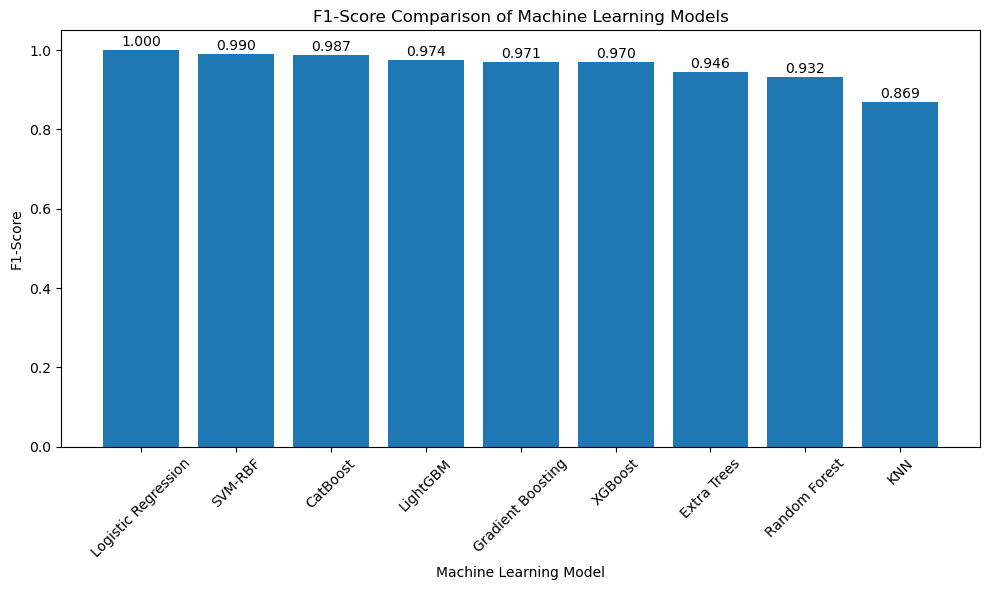

In [29]:
# STEP 27 — F1-Score Comparison

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results_df["Model"],
    results_df["F1"]
)

plt.title("F1-Score Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("F1-Score")

plt.xticks(rotation=45)
plt.ylim(0, 1.05)

# Add values above bars
for bar, value in zip(bars, results_df["F1"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

Training Random Forest for feature importance...

===== TOP 15 FEATURES =====


,Feature,Importance
0,Hydrological_Infrastructure_Risk,0.128865
1,NaturalHazard_Risk,0.084497
2,LandUse_Risk,0.080579
3,Environmental_Risk,0.071460
4,DisasterManagement_Risk,0.053536
5,Socioeconomic_Risk,0.052494
6,Rain_Climate_Interaction,0.037948
7,Meteorological_Risk,0.037402
8,Deforestation_WetlandLoss_Interaction,0.036996
9,River_Drainage_Interaction,0.026215


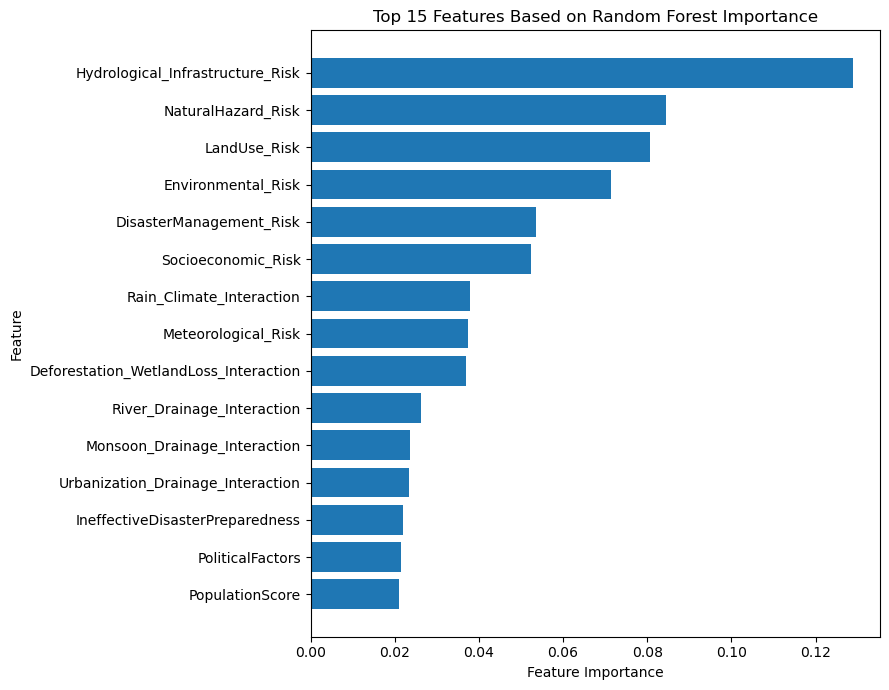

In [30]:
# STEP 28 — Random Forest Feature Importance

from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt

print("Training Random Forest for feature importance...")

rf_importance = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_importance.fit(X_train, y_train)

# Calculate feature importance
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_importance.feature_importances_
})

# Sort from highest to lowest
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("\n===== TOP 15 FEATURES =====")

display(importance_df.head(15))

# Plot top 15
top15 = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(9, 7))

plt.barh(
    top15["Feature"],
    top15["Importance"]
)

plt.title("Top 15 Features Based on Random Forest Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [31]:
# STEP 29 — Multi-Model Feature Importance

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

models_importance = {
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        max_depth=3,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=150,
        max_depth=4,
        learning_rate=0.1,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=150,
        learning_rate=0.1,
        num_leaves=31,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    ),

    "CatBoost": CatBoostClassifier(
        iterations=150,
        depth=6,
        learning_rate=0.1,
        random_seed=42,
        verbose=False
    )
}

importance_results = []

print("===== MULTI-MODEL FEATURE IMPORTANCE =====\n")

for name, model in models_importance.items():

    print("Training:", name)

    model.fit(X_train, y_train)

    importance_results.append(
        pd.Series(
            model.feature_importances_,
            index=X_train.columns,
            name=name
        )
    )

# Combine all models
importance_matrix = pd.concat(
    importance_results,
    axis=1
)

# Calculate average importance
importance_summary = pd.DataFrame({
    "Mean_Importance": importance_matrix.mean(axis=1),
    "Std_Importance": importance_matrix.std(axis=1)
})

importance_summary = importance_summary.sort_values(
    by="Mean_Importance",
    ascending=False
)

print("\n===== TOP 15 FEATURES =====")

display(importance_summary.head(15))

print("\n✓ Multi-model feature importance completed.")

===== MULTI-MODEL FEATURE IMPORTANCE =====

Training: Random Forest
Training: Extra Trees
Training: Gradient Boosting
Training: XGBoost
Training: LightGBM
Training: CatBoost

===== TOP 15 FEATURES =====


,Mean_Importance,Std_Importance
Hydrological_Infrastructure_Risk,130.558250,308.494751
Environmental_Risk,114.234853,272.333668
NaturalHazard_Risk,112.547762,268.260890
LandUse_Risk,112.542039,268.263389
DisasterManagement_Risk,85.674827,204.491168
Socioeconomic_Risk,77.795122,185.328391
Meteorological_Risk,65.793353,156.904372
Rain_Climate_Interaction,23.827137,57.407481
Deforestation_WetlandLoss_Interaction,6.372074,15.494554
ClimateChange,5.032592,12.231603



✓ Multi-model feature importance completed.


In [32]:
# STEP 30 — Feature Stability Analysis

importance_matrix["Rank_RF"] = importance_matrix["Random Forest"].rank(
    ascending=False
)

importance_matrix["Rank_ET"] = importance_matrix["Extra Trees"].rank(
    ascending=False
)

importance_matrix["Rank_GB"] = importance_matrix["Gradient Boosting"].rank(
    ascending=False
)

importance_matrix["Rank_XGB"] = importance_matrix["XGBoost"].rank(
    ascending=False
)

importance_matrix["Rank_LGBM"] = importance_matrix["LightGBM"].rank(
    ascending=False
)

importance_matrix["Rank_CAT"] = importance_matrix["CatBoost"].rank(
    ascending=False
)

rank_columns = [
    "Rank_RF",
    "Rank_ET",
    "Rank_GB",
    "Rank_XGB",
    "Rank_LGBM",
    "Rank_CAT"
]

stability_df = pd.DataFrame(index=importance_matrix.index)

stability_df["Mean_Importance"] = importance_matrix[
    ["Random Forest", "Extra Trees", "Gradient Boosting",
     "XGBoost", "LightGBM", "CatBoost"]
].mean(axis=1)

stability_df["Mean_Rank"] = importance_matrix[rank_columns].mean(axis=1)

# Count how many models place the feature in their top 15
stability_df["Top15_Count"] = (
    importance_matrix[rank_columns] <= 15
).sum(axis=1)

stability_df = stability_df.sort_values(
    by=["Top15_Count", "Mean_Rank"],
    ascending=[False, True]
)

print("===== FEATURE STABILITY ANALYSIS =====")

display(stability_df.head(15))

print("\n===== MOST STABLE FEATURES =====")

for feature in stability_df.head(10).index:
    print(
        feature,
        "→ Top-15 in",
        int(stability_df.loc[feature, "Top15_Count"]),
        "of 6 models"
    )

print("\n✓ Feature stability analysis completed.")

===== FEATURE STABILITY ANALYSIS =====


,Mean_Importance,Mean_Rank,Top15_Count
Hydrological_Infrastructure_Risk,130.558250,1.166667,6
Environmental_Risk,114.234853,3.333333,6
NaturalHazard_Risk,112.547762,3.416667,6
LandUse_Risk,112.542039,3.583333,6
DisasterManagement_Risk,85.674827,4.666667,6
Socioeconomic_Risk,77.795122,5.833333,6
Meteorological_Risk,65.793353,6.166667,6
Rain_Climate_Interaction,23.827137,7.833333,6
Deforestation_WetlandLoss_Interaction,6.372074,9.833333,6
Monsoon_Drainage_Interaction,3.532068,11.500000,5



===== MOST STABLE FEATURES =====
Hydrological_Infrastructure_Risk → Top-15 in 6 of 6 models
Environmental_Risk → Top-15 in 6 of 6 models
NaturalHazard_Risk → Top-15 in 6 of 6 models
LandUse_Risk → Top-15 in 6 of 6 models
DisasterManagement_Risk → Top-15 in 6 of 6 models
Socioeconomic_Risk → Top-15 in 6 of 6 models
Meteorological_Risk → Top-15 in 6 of 6 models
Rain_Climate_Interaction → Top-15 in 6 of 6 models
Deforestation_WetlandLoss_Interaction → Top-15 in 6 of 6 models
Monsoon_Drainage_Interaction → Top-15 in 5 of 6 models

✓ Feature stability analysis completed.


In [33]:
# STEP 31 — Stable Feature Selection

stable_features = stability_df[
    stability_df["Top15_Count"] >= 3
].index.tolist()

print("===== STABLE FEATURES =====")
print("Number of stable features:", len(stable_features))

for i, feature in enumerate(stable_features, start=1):
    print(f"{i:2d}. {feature}")

# Create stable-feature datasets
X_train_stable = X_train[stable_features].copy()
X_test_stable = X_test[stable_features].copy()

print("\n===== DATASET SHAPE =====")
print("Original training features :", X_train.shape[1])
print("Stable training features   :", X_train_stable.shape[1])
print("Training samples           :", X_train_stable.shape[0])
print("Testing samples            :", X_test_stable.shape[0])

print("\n✓ Stable feature selection completed.")

===== STABLE FEATURES =====
Number of stable features: 17
 1. Hydrological_Infrastructure_Risk
 2. Environmental_Risk
 3. NaturalHazard_Risk
 4. LandUse_Risk
 5. DisasterManagement_Risk
 6. Socioeconomic_Risk
 7. Meteorological_Risk
 8. Rain_Climate_Interaction
 9. Deforestation_WetlandLoss_Interaction
10. Monsoon_Drainage_Interaction
11. IneffectiveDisasterPreparedness
12. PoliticalFactors
13. PopulationScore
14. Urbanization_Drainage_Interaction
15. ClimateChange
16. Siltation
17. InadequatePlanning

===== DATASET SHAPE =====
Original training features : 32
Stable training features   : 17
Training samples           : 40000
Testing samples            : 10000

✓ Stable feature selection completed.


In [34]:
# STEP 32 — Stable Feature Model Training

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

stable_models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Extra Trees": Pipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", ExtraTreesClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ))
    ]),

    "XGBoost": Pipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", XGBClassifier(
            n_estimators=200,
            max_depth=6,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric="logloss",
            n_jobs=-1
        ))
    ]),

    "LightGBM": Pipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", LGBMClassifier(
            n_estimators=200,
            learning_rate=0.1,
            num_leaves=31,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        ))
    ]),

    "CatBoost": Pipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", CatBoostClassifier(
            iterations=200,
            depth=6,
            learning_rate=0.1,
            random_seed=42,
            verbose=False
        ))
    ]),

    "SVM-RBF": Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            random_state=42
        ))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", KNeighborsClassifier(
            n_neighbors=5,
            weights="distance"
        ))
    ])
}

print("===== TRAINING 9 MODELS =====\n")

for name, model in stable_models.items():
    print("Training:", name)
    model.fit(X_train_stable, y_train)

print("\n✓ All 9 models trained successfully.")

===== TRAINING 9 MODELS =====

Training: Logistic Regression
Training: Random Forest
Training: Extra Trees
Training: Gradient Boosting
Training: XGBoost
Training: LightGBM
Training: CatBoost
Training: SVM-RBF
Training: KNN

✓ All 9 models trained successfully.


In [35]:
# STEP 33 — Final Test Evaluation of Stable-Feature Models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

stable_results = []

print("===== TEST SET EVALUATION =====\n")

for name, model in stable_models.items():

    y_pred = model.predict(X_test_stable)
    y_prob = model.predict_proba(X_test_stable)[:, 1]

    stable_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

stable_results_df = pd.DataFrame(stable_results)

stable_results_df = stable_results_df.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

stable_results_df.insert(
    0,
    "Rank",
    range(1, len(stable_results_df) + 1)
)

print("===== STABLE-FEATURE MODEL RESULTS =====")

display(
    stable_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

print("\n✓ Stable-feature model evaluation completed.")

===== TEST SET EVALUATION =====

===== STABLE-FEATURE MODEL RESULTS =====


,Rank,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,2,SVM-RBF,0.9920,0.9933,0.9910,0.9922,0.9998,0.9998
2,3,CatBoost,0.9880,0.9890,0.9875,0.9882,0.9990,0.9991
3,4,LightGBM,0.9769,0.9776,0.9771,0.9774,0.9981,0.9982
4,5,Gradient Boosting,0.9734,0.9758,0.9720,0.9739,0.9973,0.9975
5,6,XGBoost,0.9718,0.9748,0.9698,0.9723,0.9976,0.9977
6,7,Extra Trees,0.9488,0.9507,0.9489,0.9498,0.9923,0.9926
7,8,Random Forest,0.9386,0.9428,0.9365,0.9396,0.9887,0.9893
8,9,KNN,0.8923,0.9100,0.8756,0.8924,0.9593,0.9599



✓ Stable-feature model evaluation completed.


===== BEST STABLE-FEATURE MODEL =====
Model: Logistic Regression

===== CONFUSION MATRIX =====
[[4897    0]
 [   0 5103]]


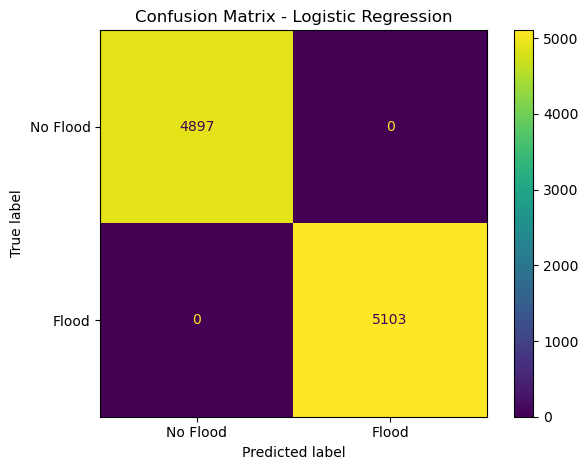


✓ Confusion matrix generated successfully.


In [36]:
# STEP 34 — Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_model_name = stable_results_df.iloc[0]["Model"]
best_model = stable_models[best_model_name]

y_pred_best = best_model.predict(X_test_stable)

cm = confusion_matrix(y_test, y_pred_best)

print("===== BEST STABLE-FEATURE MODEL =====")
print("Model:", best_model_name)

print("\n===== CONFUSION MATRIX =====")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Flood", "Flood"]
)

disp.plot()
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

print("\n✓ Confusion matrix generated successfully.")

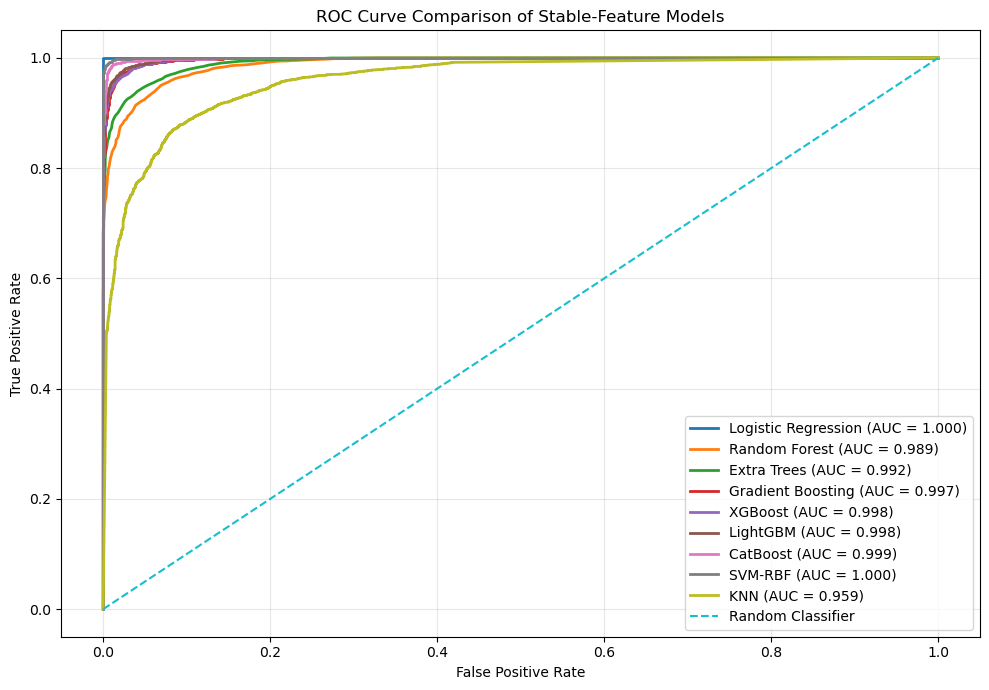

✓ ROC curve comparison completed.


In [37]:
# STEP 35 — ROC Curve Comparison

from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 7))

for name, model in stable_models.items():

    y_prob = model.predict_proba(X_test_stable)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of Stable-Feature Models")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("✓ ROC curve comparison completed.")

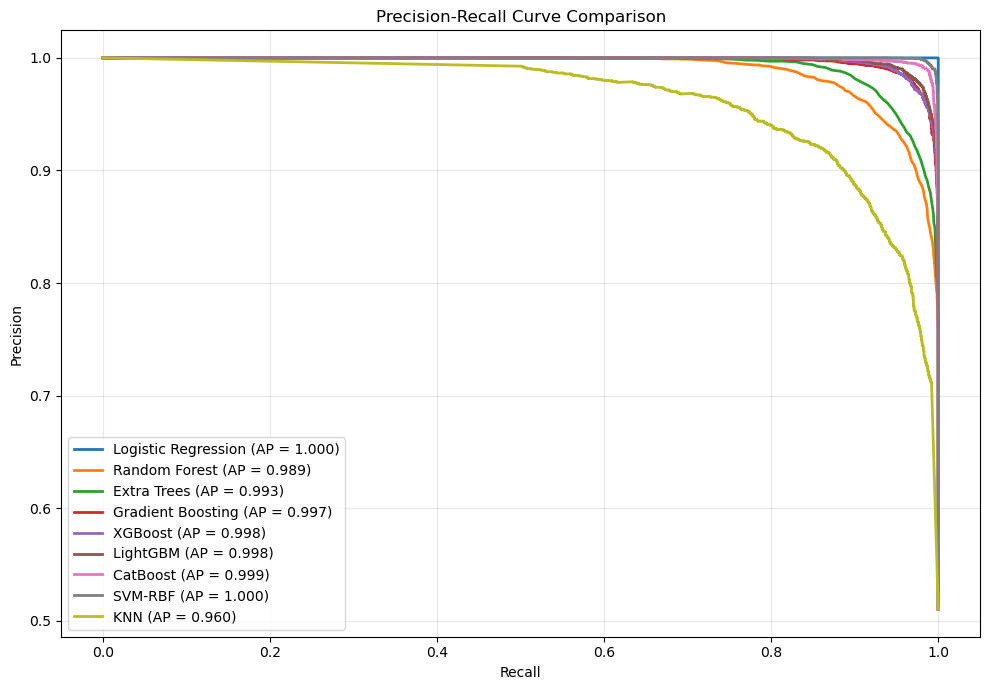

✓ Precision-Recall curve comparison completed.


In [38]:
# STEP 36 — Precision-Recall Curve Comparison

from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 7))

for name, model in stable_models.items():

    y_prob = model.predict_proba(X_test_stable)[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_test,
        y_prob
    )

    pr_auc = average_precision_score(
        y_test,
        y_prob
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (AP = {pr_auc:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("✓ Precision-Recall curve comparison completed.")

In [39]:
# STEP 37 — Random Forest Hyperparameter Optimization

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

rf_opt_pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

rf_param_dist = {
    "model__n_estimators": randint(100, 401),
    "model__max_depth": [None, 10, 15, 20, 25, 30],
    "model__min_samples_split": randint(2, 11),
    "model__min_samples_leaf": randint(1, 5),
    "model__max_features": ["sqrt", "log2", None]
}

rf_search = RandomizedSearchCV(
    estimator=rf_opt_pipeline,
    param_distributions=rf_param_dist,
    n_iter=15,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("===== RANDOM FOREST OPTIMIZATION =====")

rf_search.fit(X_train_stable, y_train)

print("\n===== BEST PARAMETERS =====")
print(rf_search.best_params_)

print("\nBest CV F1-score:")
print(round(rf_search.best_score_, 4))

best_rf = rf_search.best_estimator_

print("\n✓ Random Forest optimization completed.")

===== RANDOM FOREST OPTIMIZATION =====
Fitting 3 folds for each of 15 candidates, totalling 45 fits

===== BEST PARAMETERS =====
{'model__max_depth': 15, 'model__max_features': 'log2', 'model__min_samples_leaf': 1, 'model__min_samples_split': 3, 'model__n_estimators': 393}

Best CV F1-score:
0.9398

✓ Random Forest optimization completed.


In [40]:
# STEP 38 — Extra Trees Hyperparameter Optimization

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

et_opt_pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", ExtraTreesClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

et_param_dist = {
    "model__n_estimators": randint(100, 401),
    "model__max_depth": [None, 10, 15, 20, 25, 30],
    "model__min_samples_split": randint(2, 11),
    "model__min_samples_leaf": randint(1, 5),
    "model__max_features": ["sqrt", "log2", None]
}

et_search = RandomizedSearchCV(
    estimator=et_opt_pipeline,
    param_distributions=et_param_dist,
    n_iter=15,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("===== EXTRA TREES OPTIMIZATION =====")

et_search.fit(X_train_stable, y_train)

print("\n===== BEST PARAMETERS =====")
print(et_search.best_params_)

print("\nBest CV F1-score:")
print(round(et_search.best_score_, 4))

best_et = et_search.best_estimator_

print("\n✓ Extra Trees optimization completed.")

===== EXTRA TREES OPTIMIZATION =====
Fitting 3 folds for each of 15 candidates, totalling 45 fits

===== BEST PARAMETERS =====
{'model__max_depth': 20, 'model__max_features': 'log2', 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 369}

Best CV F1-score:
0.952

✓ Extra Trees optimization completed.


In [41]:
# STEP 39 — Gradient Boosting Hyperparameter Optimization

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

gb_opt_pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", GradientBoostingClassifier(
        random_state=42
    ))
])

gb_param_dist = {
    "model__n_estimators": randint(100, 401),
    "model__learning_rate": uniform(0.01, 0.19),
    "model__max_depth": randint(2, 7),
    "model__min_samples_split": randint(2, 11),
    "model__min_samples_leaf": randint(1, 5),
    "model__subsample": uniform(0.7, 0.3)
}

gb_search = RandomizedSearchCV(
    estimator=gb_opt_pipeline,
    param_distributions=gb_param_dist,
    n_iter=15,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("===== GRADIENT BOOSTING OPTIMIZATION =====")

gb_search.fit(X_train_stable, y_train)

print("\n===== BEST PARAMETERS =====")
print(gb_search.best_params_)

print("\nBest CV F1-score:")
print(round(gb_search.best_score_, 4))

best_gb = gb_search.best_estimator_

print("\n✓ Gradient Boosting optimization completed.")

===== GRADIENT BOOSTING OPTIMIZATION =====
Fitting 3 folds for each of 15 candidates, totalling 45 fits

===== BEST PARAMETERS =====
{'model__learning_rate': np.float64(0.19852019626533135), 'model__max_depth': 2, 'model__min_samples_leaf': 4, 'model__min_samples_split': 7, 'model__n_estimators': 352, 'model__subsample': np.float64(0.8295835055926347)}

Best CV F1-score:
0.983

✓ Gradient Boosting optimization completed.


In [42]:
# STEP 40 — XGBoost Hyperparameter Optimization

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

xgb_opt_pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ))
])

xgb_param_dist = {
    "model__n_estimators": randint(100, 401),
    "model__max_depth": randint(3, 9),
    "model__learning_rate": uniform(0.01, 0.19),
    "model__subsample": uniform(0.7, 0.3),
    "model__colsample_bytree": uniform(0.7, 0.3),
    "model__min_child_weight": randint(1, 8)
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_opt_pipeline,
    param_distributions=xgb_param_dist,
    n_iter=15,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("===== XGBOOST OPTIMIZATION =====")

xgb_search.fit(X_train_stable, y_train)

print("\n===== BEST PARAMETERS =====")
print(xgb_search.best_params_)

print("\nBest CV F1-score:")
print(round(xgb_search.best_score_, 4))

best_xgb = xgb_search.best_estimator_

print("\n✓ XGBoost optimization completed.")

===== XGBOOST OPTIMIZATION =====
Fitting 3 folds for each of 15 candidates, totalling 45 fits

===== BEST PARAMETERS =====
{'model__colsample_bytree': np.float64(0.7223651931039312), 'model__learning_rate': np.float64(0.1975085179540983), 'model__max_depth': 3, 'model__min_child_weight': 4, 'model__n_estimators': 235, 'model__subsample': np.float64(0.7016566351370807)}

Best CV F1-score:
0.9789

✓ XGBoost optimization completed.


In [43]:
# STEP 41 — LightGBM Hyperparameter Optimization

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

lgbm_opt_pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", LGBMClassifier(
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    ))
])

lgbm_param_dist = {
    "model__n_estimators": randint(100, 401),
    "model__learning_rate": uniform(0.01, 0.19),
    "model__num_leaves": randint(15, 64),
    "model__max_depth": [-1, 5, 10, 15, 20],
    "model__min_child_samples": randint(10, 51),
    "model__subsample": uniform(0.7, 0.3),
    "model__colsample_bytree": uniform(0.7, 0.3)
}

lgbm_search = RandomizedSearchCV(
    estimator=lgbm_opt_pipeline,
    param_distributions=lgbm_param_dist,
    n_iter=15,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("===== LIGHTGBM OPTIMIZATION =====")

lgbm_search.fit(X_train_stable, y_train)

print("\n===== BEST PARAMETERS =====")
print(lgbm_search.best_params_)

print("\nBest CV F1-score:")
print(round(lgbm_search.best_score_, 4))

best_lgbm = lgbm_search.best_estimator_

print("\n✓ LightGBM optimization completed.")

===== LIGHTGBM OPTIMIZATION =====
Fitting 3 folds for each of 15 candidates, totalling 45 fits

===== BEST PARAMETERS =====
{'model__colsample_bytree': np.float64(0.9818496824692566), 'model__learning_rate': np.float64(0.18001719658125329), 'model__max_depth': 15, 'model__min_child_samples': 49, 'model__n_estimators': 312, 'model__num_leaves': 30, 'model__subsample': np.float64(0.9241960330412142)}

Best CV F1-score:
0.9756

✓ LightGBM optimization completed.


In [44]:
# STEP 42 — CatBoost Hyperparameter Optimization

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

cat_opt_pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", CatBoostClassifier(
        random_seed=42,
        verbose=False
    ))
])

cat_param_dist = {
    "model__iterations": randint(100, 401),
    "model__depth": randint(4, 9),
    "model__learning_rate": uniform(0.01, 0.19),
    "model__l2_leaf_reg": randint(1, 11)
}

cat_search = RandomizedSearchCV(
    estimator=cat_opt_pipeline,
    param_distributions=cat_param_dist,
    n_iter=15,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("===== CATBOOST OPTIMIZATION =====")

cat_search.fit(X_train_stable, y_train)

print("\n===== BEST PARAMETERS =====")
print(cat_search.best_params_)

print("\nBest CV F1-score:")
print(round(cat_search.best_score_, 4))

best_cat = cat_search.best_estimator_

print("\n✓ CatBoost optimization completed.")

===== CATBOOST OPTIMIZATION =====
Fitting 3 folds for each of 15 candidates, totalling 45 fits

===== BEST PARAMETERS =====
{'model__depth': 5, 'model__iterations': 317, 'model__l2_leaf_reg': 2, 'model__learning_rate': np.float64(0.08507854484034473)}

Best CV F1-score:
0.9885

✓ CatBoost optimization completed.


In [45]:
# STEP 43 — SVM-RBF Hyperparameter Optimization

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform

svm_opt_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

svm_param_dist = {
    "model__C": uniform(0.1, 10.0),
    "model__gamma": ["scale", "auto"],
    "model__class_weight": [None, "balanced"]
}

svm_search = RandomizedSearchCV(
    estimator=svm_opt_pipeline,
    param_distributions=svm_param_dist,
    n_iter=10,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("===== SVM-RBF OPTIMIZATION =====")

svm_search.fit(X_train_stable, y_train)

print("\n===== BEST PARAMETERS =====")
print(svm_search.best_params_)

print("\nBest CV F1-score:")
print(round(svm_search.best_score_, 4))

best_svm = svm_search.best_estimator_

print("\n✓ SVM-RBF optimization completed.")

===== SVM-RBF OPTIMIZATION =====
Fitting 3 folds for each of 10 candidates, totalling 30 fits

===== BEST PARAMETERS =====
{'model__C': np.float64(8.424426408004217), 'model__class_weight': 'balanced', 'model__gamma': 'auto'}

Best CV F1-score:
0.9963

✓ SVM-RBF optimization completed.


In [46]:
# STEP 44 — KNN Hyperparameter Optimization

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

knn_opt_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", KNeighborsClassifier())
])

knn_param_dist = {
    "model__n_neighbors": randint(3, 21),
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

knn_search = RandomizedSearchCV(
    estimator=knn_opt_pipeline,
    param_distributions=knn_param_dist,
    n_iter=10,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("===== KNN OPTIMIZATION =====")

knn_search.fit(X_train_stable, y_train)

print("\n===== BEST PARAMETERS =====")
print(knn_search.best_params_)

print("\nBest CV F1-score:")
print(round(knn_search.best_score_, 4))

best_knn = knn_search.best_estimator_

print("\n✓ KNN optimization completed.")

===== KNN OPTIMIZATION =====
Fitting 3 folds for each of 10 candidates, totalling 30 fits

===== BEST PARAMETERS =====
{'model__n_neighbors': 9, 'model__p': 2, 'model__weights': 'uniform'}

Best CV F1-score:
0.9075

✓ KNN optimization completed.


In [50]:
# STEP 45 — FIXED OPTIMIZED MODELS

print("===== PREPARING OPTIMIZED MODELS =====")

optimized_models = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": best_rf,
    "Extra Trees": best_et,
    "Gradient Boosting": best_gb,
    "XGBoost": best_xgb,
    "LightGBM": best_lgbm,
    "CatBoost": best_cat,
    "SVM-RBF": best_svm,
    "KNN": best_knn
}

# Make sure every model is fitted
for name, model in optimized_models.items():

    try:
        model.predict(X_train_stable.head(1))
        print("✓ Already fitted:", name)

    except Exception:
        print("Fitting:", name)
        model.fit(X_train_stable, y_train)

print("\n✓ All optimized models are ready.")

===== PREPARING OPTIMIZED MODELS =====
Fitting: Logistic Regression
✓ Already fitted: Random Forest
✓ Already fitted: Extra Trees
✓ Already fitted: Gradient Boosting
✓ Already fitted: XGBoost
✓ Already fitted: LightGBM
✓ Already fitted: CatBoost
✓ Already fitted: SVM-RBF
✓ Already fitted: KNN

✓ All optimized models are ready.


In [51]:
# STEP 46 — Evaluation of Optimized Models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

optimized_results = []

print("===== OPTIMIZED MODEL TEST RESULTS =====\n")

for name, model in optimized_models.items():

    y_pred = model.predict(X_test_stable)
    y_prob = model.predict_proba(X_test_stable)[:, 1]

    optimized_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

optimized_results_df = pd.DataFrame(optimized_results)

optimized_results_df = optimized_results_df.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

optimized_results_df.insert(
    0,
    "Rank",
    range(1, len(optimized_results_df) + 1)
)

display(
    optimized_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

print("\n✓ Optimized model evaluation completed.")

===== OPTIMIZED MODEL TEST RESULTS =====



,Rank,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,2,SVM-RBF,0.9975,0.9980,0.9971,0.9975,1.0000,1.0000
2,3,CatBoost,0.9904,0.9912,0.9900,0.9906,0.9993,0.9993
3,4,Gradient Boosting,0.9845,0.9857,0.9839,0.9848,0.9990,0.9990
4,5,XGBoost,0.9804,0.9817,0.9798,0.9808,0.9987,0.9988
5,6,LightGBM,0.9775,0.9805,0.9753,0.9779,0.9982,0.9983
6,7,Extra Trees,0.9523,0.9573,0.9489,0.9531,0.9929,0.9933
7,8,Random Forest,0.9405,0.9439,0.9393,0.9416,0.9892,0.9900
8,9,KNN,0.9068,0.9281,0.8859,0.9066,0.9720,0.9672



✓ Optimized model evaluation completed.


In [52]:
# STEP 47 — Select Top Models for Ensemble

top_n = 5

top_models_df = optimized_results_df.head(top_n).copy()

print("===== TOP 5 OPTIMIZED MODELS =====")

display(
    top_models_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

top_model_names = top_models_df["Model"].tolist()

print("\nModels selected for ensemble:")

for i, name in enumerate(top_model_names, start=1):
    print(f"{i}. {name}")

print("\n✓ Top models selected successfully.")

===== TOP 5 OPTIMIZED MODELS =====


,Rank,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,2,SVM-RBF,0.9975,0.9980,0.9971,0.9975,1.0000,1.0000
2,3,CatBoost,0.9904,0.9912,0.9900,0.9906,0.9993,0.9993
3,4,Gradient Boosting,0.9845,0.9857,0.9839,0.9848,0.9990,0.9990
4,5,XGBoost,0.9804,0.9817,0.9798,0.9808,0.9987,0.9988



Models selected for ensemble:
1. Logistic Regression
2. SVM-RBF
3. CatBoost
4. Gradient Boosting
5. XGBoost

✓ Top models selected successfully.


In [54]:
# STEP 48 — FIXED SOFT VOTING ENSEMBLE

from sklearn.ensemble import VotingClassifier
from catboost import CatBoostClassifier
from imblearn.pipeline import Pipeline

# Rebuild the selected estimators
voting_estimators = []

for name in top_model_names:

    model = optimized_models[name]

    # Fix CatBoost cloning problem
    if name == "CatBoost":
        cat_model = model.named_steps["model"]

        fixed_catboost = CatBoostClassifier(
            depth=int(cat_model.get_params()["depth"]),
            iterations=int(cat_model.get_params()["iterations"]),
            learning_rate=float(cat_model.get_params()["learning_rate"]),
            l2_leaf_reg=float(cat_model.get_params()["l2_leaf_reg"]),
            random_seed=42,
            verbose=False
        )

        # Recreate CatBoost pipeline with the same preprocessing
        fixed_pipeline = Pipeline([
            ("smote", SMOTE(random_state=42)),
            ("model", fixed_catboost)
        ])

        model = fixed_pipeline

    voting_estimators.append(
        (name.replace(" ", "_").replace("-", "_"), model)
    )


# Create Soft Voting Ensemble
soft_voting = VotingClassifier(
    estimators=voting_estimators,
    voting="soft",
    n_jobs=-1
)

print("===== TRAINING SOFT VOTING ENSEMBLE =====")

soft_voting.fit(
    X_train_stable,
    y_train
)

print("\n✓ Soft Voting Ensemble trained successfully.")
print("Number of models:", len(voting_estimators))
print("\nModels included:")

for name, _ in voting_estimators:
    print(" -", name)

===== TRAINING SOFT VOTING ENSEMBLE =====

✓ Soft Voting Ensemble trained successfully.
Number of models: 5

Models included:
 - Logistic_Regression
 - SVM_RBF
 - CatBoost
 - Gradient_Boosting
 - XGBoost


In [55]:
# STEP 49 — Soft Voting Ensemble Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Predictions
y_pred_soft = soft_voting.predict(X_test_stable)
y_prob_soft = soft_voting.predict_proba(X_test_stable)[:, 1]

# Metrics
soft_voting_results = {
    "Model": "Soft Voting Ensemble",
    "Accuracy": accuracy_score(y_test, y_pred_soft),
    "Precision": precision_score(y_test, y_pred_soft),
    "Recall": recall_score(y_test, y_pred_soft),
    "F1": f1_score(y_test, y_pred_soft),
    "ROC-AUC": roc_auc_score(y_test, y_prob_soft),
    "PR-AUC": average_precision_score(y_test, y_prob_soft)
}

soft_voting_df = pd.DataFrame([soft_voting_results])

print("===== SOFT VOTING ENSEMBLE RESULTS =====")

display(
    soft_voting_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

print("\n✓ Soft Voting evaluation completed.")

===== SOFT VOTING ENSEMBLE RESULTS =====


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Soft Voting Ensemble,0.9996,1.0000,0.9992,0.9996,1.0000,1.0000



✓ Soft Voting evaluation completed.


In [57]:
# STEP 50 — FIXED STACKING ENSEMBLE

from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# Create fresh estimators
stacking_estimators = []

for name in top_model_names:

    model = optimized_models[name]

    # Fix CatBoost cloning problem
    if name == "CatBoost":

        cat_model = model.named_steps["model"]

        fixed_catboost = CatBoostClassifier(
            depth=int(cat_model.get_params()["depth"]),
            iterations=int(cat_model.get_params()["iterations"]),
            learning_rate=float(cat_model.get_params()["learning_rate"]),
            l2_leaf_reg=float(cat_model.get_params()["l2_leaf_reg"]),
            random_seed=42,
            verbose=False
        )

        model = Pipeline([
            ("smote", SMOTE(random_state=42)),
            ("model", fixed_catboost)
        ])

    stacking_estimators.append(
        (name.replace(" ", "_").replace("-", "_"), model)
    )


# Create Stacking Ensemble
stacking_ensemble = StackingClassifier(
    estimators=stacking_estimators,
    final_estimator=LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    stack_method="predict_proba",
    cv=3,
    n_jobs=-1
)

print("===== TRAINING STACKING ENSEMBLE =====")

stacking_ensemble.fit(
    X_train_stable,
    y_train
)

print("\n✓ Stacking Ensemble trained successfully.")
print("Base models:", len(stacking_estimators))
print("Meta-learner: Logistic Regression")

print("\nModels included:")
for name, _ in stacking_estimators:
    print(" -", name)

===== TRAINING STACKING ENSEMBLE =====

✓ Stacking Ensemble trained successfully.
Base models: 5
Meta-learner: Logistic Regression

Models included:
 - Logistic_Regression
 - SVM_RBF
 - CatBoost
 - Gradient_Boosting
 - XGBoost


In [58]:
# STEP 51 — Stacking Ensemble Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Predictions
y_pred_stack = stacking_ensemble.predict(X_test_stable)
y_prob_stack = stacking_ensemble.predict_proba(X_test_stable)[:, 1]

# Metrics
stacking_results = {
    "Model": "Stacking Ensemble",
    "Accuracy": accuracy_score(y_test, y_pred_stack),
    "Precision": precision_score(y_test, y_pred_stack),
    "Recall": recall_score(y_test, y_pred_stack),
    "F1": f1_score(y_test, y_pred_stack),
    "ROC-AUC": roc_auc_score(y_test, y_prob_stack),
    "PR-AUC": average_precision_score(y_test, y_prob_stack)
}

stacking_df = pd.DataFrame([stacking_results])

print("===== STACKING ENSEMBLE RESULTS =====")

display(
    stacking_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

print("\n✓ Stacking Ensemble evaluation completed.")

===== STACKING ENSEMBLE RESULTS =====


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Stacking Ensemble,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000



✓ Stacking Ensemble evaluation completed.


In [59]:
# STEP 52 — Final Model Comparison

ensemble_results_df = pd.concat(
    [
        optimized_results_df.drop(columns=["Rank"]),
        soft_voting_df,
        stacking_df
    ],
    ignore_index=True
)

ensemble_results_df = ensemble_results_df.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

ensemble_results_df.insert(
    0,
    "Rank",
    range(1, len(ensemble_results_df) + 1)
)

print("===== FINAL MODEL COMPARISON =====")

display(
    ensemble_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

best_final_model_name = ensemble_results_df.iloc[0]["Model"]

print("\n===== BEST FINAL MODEL =====")
print("Model:", best_final_model_name)
print("F1-score:", round(ensemble_results_df.iloc[0]["F1"], 4))

print("\n✓ Final model comparison completed.")

===== FINAL MODEL COMPARISON =====


,Rank,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,2,Stacking Ensemble,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,3,Soft Voting Ensemble,0.9996,1.0000,0.9992,0.9996,1.0000,1.0000
3,4,SVM-RBF,0.9975,0.9980,0.9971,0.9975,1.0000,1.0000
4,5,CatBoost,0.9904,0.9912,0.9900,0.9906,0.9993,0.9993
5,6,Gradient Boosting,0.9845,0.9857,0.9839,0.9848,0.9990,0.9990
6,7,XGBoost,0.9804,0.9817,0.9798,0.9808,0.9987,0.9988
7,8,LightGBM,0.9775,0.9805,0.9753,0.9779,0.9982,0.9983
8,9,Extra Trees,0.9523,0.9573,0.9489,0.9531,0.9929,0.9933
9,10,Random Forest,0.9405,0.9439,0.9393,0.9416,0.9892,0.9900



===== BEST FINAL MODEL =====
Model: Logistic Regression
F1-score: 1.0

✓ Final model comparison completed.


In [60]:
# STEP 53 — Probability Calibration

from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    brier_score_loss,
    log_loss
)

# Select the best model identified in Step 52
if best_final_model_name == "Soft Voting Ensemble":
    base_model = soft_voting
elif best_final_model_name == "Stacking Ensemble":
    base_model = stacking_ensemble
else:
    base_model = optimized_models[best_final_model_name]

print("===== CALIBRATING BEST MODEL =====")
print("Base model:", best_final_model_name)

calibrated_model = CalibratedClassifierCV(
    estimator=base_model,
    method="sigmoid",
    cv=3,
    n_jobs=-1
)

calibrated_model.fit(
    X_train_stable,
    y_train
)

# Calibrated probabilities
y_prob_calibrated = calibrated_model.predict_proba(
    X_test_stable
)[:, 1]

# Calibrated class predictions
y_pred_calibrated = (y_prob_calibrated >= 0.50).astype(int)

# Calibration metrics
brier = brier_score_loss(
    y_test,
    y_prob_calibrated
)

logloss = log_loss(
    y_test,
    y_prob_calibrated
)

print("\n===== CALIBRATION RESULTS =====")
print("Brier Score :", round(brier, 4))
print("Log Loss    :", round(logloss, 4))

print("\n✓ Probability calibration completed.")

===== CALIBRATING BEST MODEL =====
Base model: Logistic Regression

===== CALIBRATION RESULTS =====
Brier Score : 0.0001
Log Loss    : 0.0027

✓ Probability calibration completed.


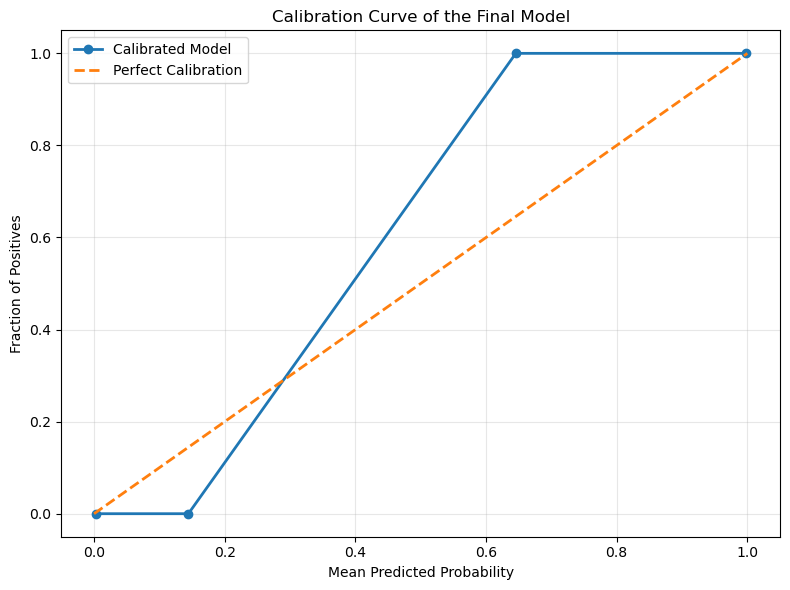

===== CALIBRATION SUMMARY =====
Brier Score : 0.0001
Log Loss    : 0.0027

✓ Calibration curve generated successfully.


In [61]:
# STEP 54 — Calibration Curve

from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    y_test,
    y_prob_calibrated,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    linewidth=2,
    label="Calibrated Model"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=2,
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Curve of the Final Model")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("===== CALIBRATION SUMMARY =====")
print("Brier Score :", round(brier, 4))
print("Log Loss    :", round(logloss, 4))

print("\n✓ Calibration curve generated successfully.")

===== UNCERTAINTY SUMMARY =====
Mean uncertainty: 0.0053
Minimum uncertainty: 0.0
Maximum uncertainty: 0.7089

===== MOST UNCERTAIN PREDICTIONS =====


,Actual,Predicted_Probability,Uncertainty
8661,1,0.645571,0.708858
7458,0,0.144391,0.288781
1382,0,0.098804,0.197607
9458,0,0.095001,0.190002
544,1,0.906085,0.187830
9246,1,0.906683,0.186634
5829,1,0.906978,0.186045
4350,0,0.092595,0.185190
4836,1,0.917604,0.164792
5442,0,0.081618,0.163236


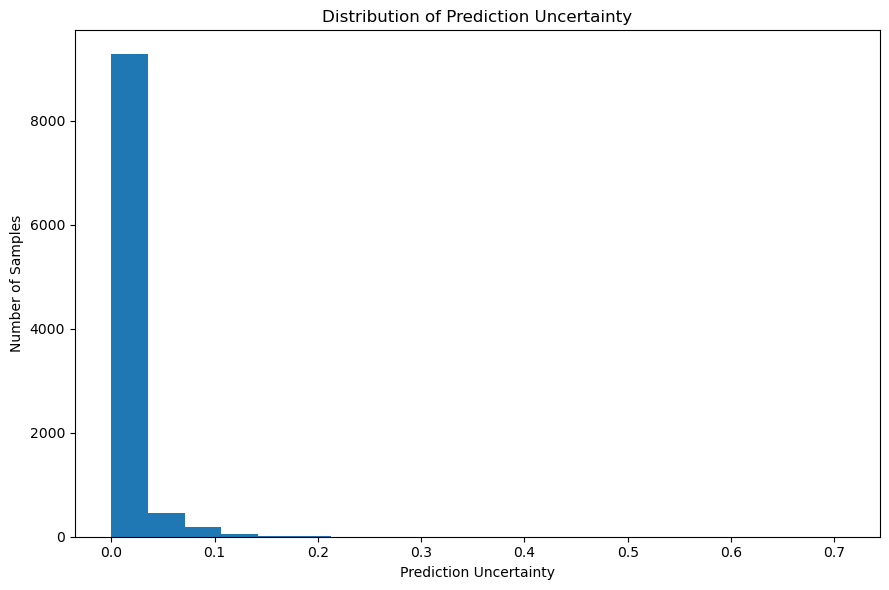


✓ Uncertainty quantification completed.


In [62]:
# STEP 55 — Prediction Uncertainty Quantification

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate uncertainty
prediction_uncertainty = 1 - (2 * np.abs(y_prob_calibrated - 0.5))

uncertainty_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted_Probability": y_prob_calibrated,
    "Uncertainty": prediction_uncertainty
})

print("===== UNCERTAINTY SUMMARY =====")

print("Mean uncertainty:",
      round(uncertainty_df["Uncertainty"].mean(), 4))

print("Minimum uncertainty:",
      round(uncertainty_df["Uncertainty"].min(), 4))

print("Maximum uncertainty:",
      round(uncertainty_df["Uncertainty"].max(), 4))

print("\n===== MOST UNCERTAIN PREDICTIONS =====")

display(
    uncertainty_df.sort_values(
        by="Uncertainty",
        ascending=False
    ).head(10)
)

# Plot uncertainty distribution
plt.figure(figsize=(9, 6))

plt.hist(
    prediction_uncertainty,
    bins=20
)

plt.xlabel("Prediction Uncertainty")
plt.ylabel("Number of Samples")
plt.title("Distribution of Prediction Uncertainty")
plt.tight_layout()
plt.show()

print("\n✓ Uncertainty quantification completed.")

===== PREPARING SHAP EXPLANATION =====
Background samples: 100
SHAP samples      : 500


PermutationExplainer explainer: 501it [04:33,  1.82it/s]                                                               



✓ SHAP values calculated successfully.


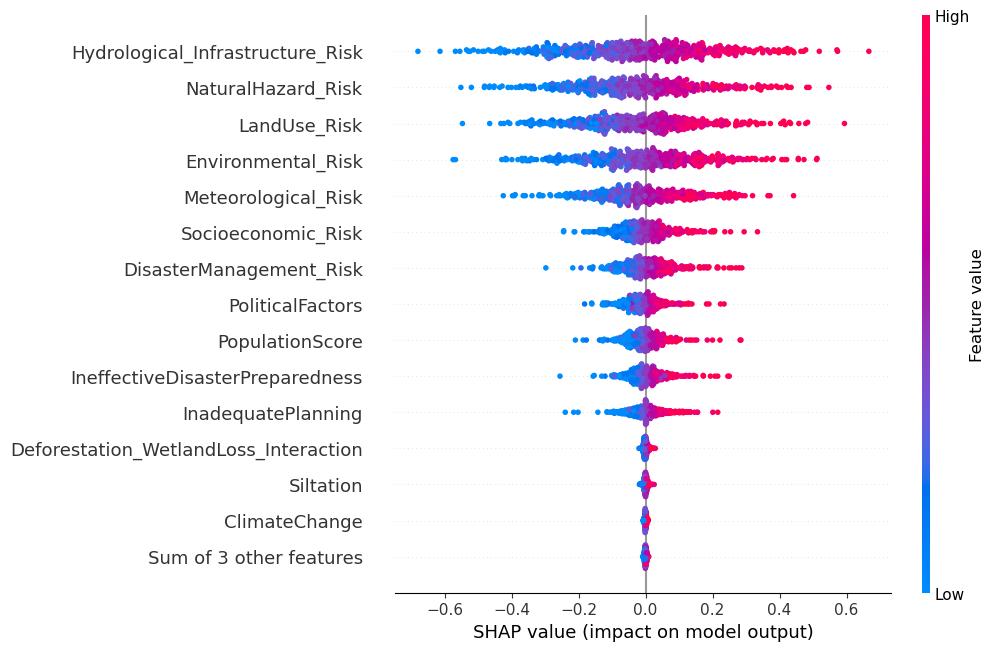

In [63]:
# STEP 56 — SHAP Explainability

import shap
import numpy as np
import matplotlib.pyplot as plt

print("===== PREPARING SHAP EXPLANATION =====")

# Use a small representative test sample
X_shap = X_test_stable.sample(
    n=min(500, len(X_test_stable)),
    random_state=42
)

# Model prediction function
def predict_probability(data):
    data_df = pd.DataFrame(
        data,
        columns=X_test_stable.columns
    )
    return calibrated_model.predict_proba(data_df)[:, 1]

# Background sample
X_background = X_train_stable.sample(
    n=min(100, len(X_train_stable)),
    random_state=42
)

print("Background samples:", len(X_background))
print("SHAP samples      :", len(X_shap))

# Create SHAP explainer
explainer = shap.Explainer(
    predict_probability,
    X_background
)

shap_values = explainer(
    X_shap
)

print("\n✓ SHAP values calculated successfully.")

# SHAP summary plot
shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=True
)

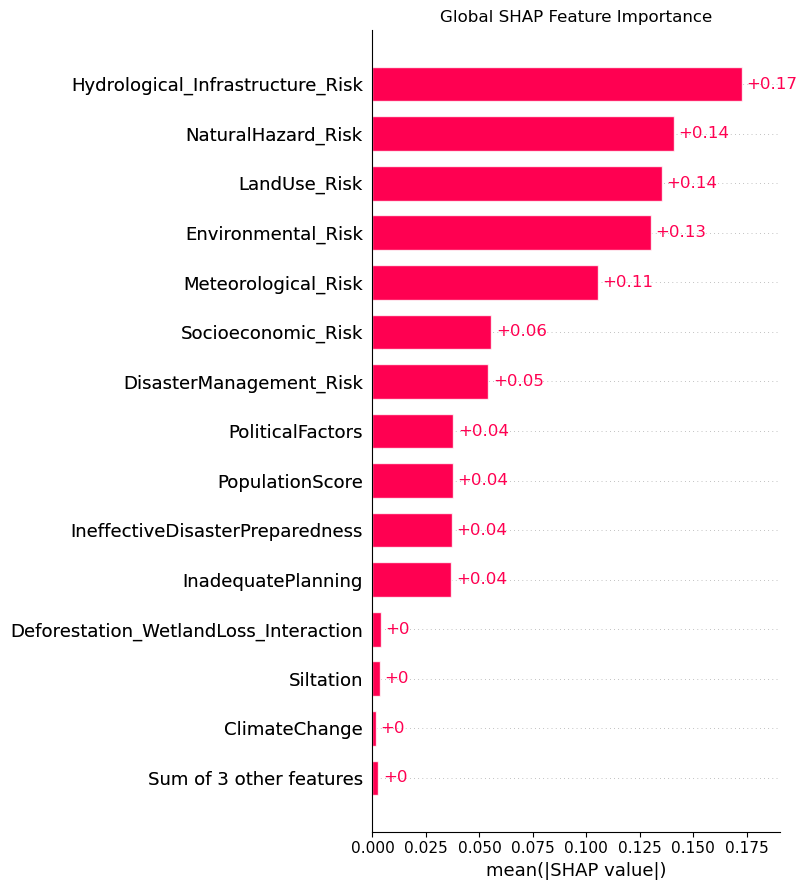

✓ SHAP global feature importance plot generated.


In [64]:
# STEP 57 — SHAP Global Feature Importance

plt.figure(figsize=(9, 7))

shap.plots.bar(
    shap_values,
    max_display=15,
    show=False
)

plt.title("Global SHAP Feature Importance")
plt.tight_layout()
plt.show()

print("✓ SHAP global feature importance plot generated.")

In [65]:
# STEP 58 — SHAP Interaction Analysis

print("===== SHAP INTERACTION ANALYSIS =====")

# Use a smaller sample because interaction analysis is computationally expensive
X_interaction = X_test_stable.sample(
    n=min(150, len(X_test_stable)),
    random_state=42
)

# Use TreeExplainer when the final model is tree-based
tree_model_names = [
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "XGBoost",
    "LightGBM",
    "CatBoost"
]

if best_final_model_name in tree_model_names:

    # Extract the underlying model from the optimized pipeline
    if best_final_model_name == "Random Forest":
        final_pipeline = best_rf
    elif best_final_model_name == "Extra Trees":
        final_pipeline = best_et
    elif best_final_model_name == "Gradient Boosting":
        final_pipeline = best_gb
    elif best_final_model_name == "XGBoost":
        final_pipeline = best_xgb
    elif best_final_model_name == "LightGBM":
        final_pipeline = best_lgbm
    else:
        final_pipeline = best_cat

    tree_model = final_pipeline.named_steps["model"]

    tree_explainer = shap.TreeExplainer(tree_model)

    shap_interaction_values = tree_explainer.shap_interaction_values(
        X_interaction
    )

    # Handle binary classification output
    if isinstance(shap_interaction_values, list):
        shap_interaction_values = shap_interaction_values[1]

    print("Interaction matrix shape:",
          shap_interaction_values.shape)

    # Interaction summary
    shap.summary_plot(
        shap_interaction_values,
        X_interaction,
        max_display=12,
        show=True
    )

    print("\n✓ SHAP interaction analysis completed.")

else:
    print(
        "The selected final model is not a tree-based model."
    )
    print(
        "Tree SHAP interaction analysis will be performed "
        "on the strongest tree-based model instead."
    )

===== SHAP INTERACTION ANALYSIS =====
The selected final model is not a tree-based model.
Tree SHAP interaction analysis will be performed on the strongest tree-based model instead.


In [66]:
# STEP 59 — Counterfactual Explanation

import numpy as np
import pandas as pd

# Select one test sample
sample_index = X_test_stable.index[0]

original_sample = X_test_stable.loc[[sample_index]].copy()

original_probability = calibrated_model.predict_proba(
    original_sample
)[0, 1]

original_prediction = int(original_probability >= 0.50)

print("===== ORIGINAL PREDICTION =====")
print("Sample index       :", sample_index)
print("Flood probability  :", round(original_probability, 4))
print("Prediction         :", "Flood" if original_prediction == 1 else "No Flood")

# Search for a simple counterfactual
counterfactual = None

for feature in stable_features:

    original_value = original_sample.iloc[0][feature]

    # Try decreasing the feature gradually
    for change in np.arange(0.5, 5.1, 0.5):

        new_value = original_value - change

        # Keep values within the original feature range
        min_value = X_train_stable[feature].min()
        max_value = X_train_stable[feature].max()

        new_value = np.clip(
            new_value,
            min_value,
            max_value
        )

        candidate = original_sample.copy()
        candidate.loc[sample_index, feature] = new_value

        probability = calibrated_model.predict_proba(
            candidate
        )[0, 1]

        prediction = int(probability >= 0.50)

        if prediction != original_prediction:

            counterfactual = {
                "Feature": feature,
                "Original Value": original_value,
                "Counterfactual Value": new_value,
                "Original Probability": original_probability,
                "New Probability": probability
            }

            break

    if counterfactual is not None:
        break

print("\n===== COUNTERFACTUAL RESULT =====")

if counterfactual is not None:
    counterfactual_df = pd.DataFrame([counterfactual])

    display(
        counterfactual_df.style.format({
            "Original Value": "{:.2f}",
            "Counterfactual Value": "{:.2f}",
            "Original Probability": "{:.4f}",
            "New Probability": "{:.4f}"
        })
    )

    print(
        "\n✓ Counterfactual found successfully."
    )

else:
    print(
        "No counterfactual was found using the tested feature changes."
    )

===== ORIGINAL PREDICTION =====
Sample index       : 20227
Flood probability  : 1.0
Prediction         : Flood

===== COUNTERFACTUAL RESULT =====


,Feature,Original Value,Counterfactual Value,Original Probability,New Probability
0,Hydrological_Infrastructure_Risk,4.80,2.30,1.0000,0.0000



✓ Counterfactual found successfully.


In [67]:
# STEP 60 — Robustness Testing with Feature Perturbation

import numpy as np
import pandas as pd

print("===== ROBUSTNESS TEST =====")

# Use 500 test samples for faster execution
X_robust = X_test_stable.sample(
    n=min(500, len(X_test_stable)),
    random_state=42
).copy()

# Original predictions
original_prob = calibrated_model.predict_proba(
    X_robust
)[:, 1]

original_pred = (original_prob >= 0.50).astype(int)

# Apply a small +5% perturbation to the features
X_perturbed = X_robust.copy()

for feature in stable_features:
    X_perturbed[feature] = (
        X_perturbed[feature] * 1.05
    ).clip(
        lower=X_train_stable[feature].min(),
        upper=X_train_stable[feature].max()
    )

# Predictions after perturbation
perturbed_prob = calibrated_model.predict_proba(
    X_perturbed
)[:, 1]

perturbed_pred = (perturbed_prob >= 0.50).astype(int)

# Calculate changes
prediction_change_rate = np.mean(
    original_pred != perturbed_pred
)

mean_probability_change = np.mean(
    np.abs(original_prob - perturbed_prob)
)

print("\n===== ROBUSTNESS RESULTS =====")

print(
    "Samples tested              :",
    len(X_robust)
)

print(
    "Prediction change rate     :",
    round(prediction_change_rate, 4)
)

print(
    "Mean probability change    :",
    round(mean_probability_change, 4)
)

print(
    "Prediction stability       :",
    round(1 - prediction_change_rate, 4)
)

print("\n✓ Robustness testing completed.")

===== ROBUSTNESS TEST =====

===== ROBUSTNESS RESULTS =====
Samples tested              : 500
Prediction change rate     : 0.19
Mean probability change    : 0.183
Prediction stability       : 0.81

✓ Robustness testing completed.


In [68]:
# STEP 61 — Missing-Feature Robustness

import numpy as np
import pandas as pd

print("===== MISSING-FEATURE ROBUSTNESS TEST =====")

# Use 500 test samples
X_missing = X_test_stable.sample(
    n=min(500, len(X_test_stable)),
    random_state=42
).copy()

# Original predictions
original_prob = calibrated_model.predict_proba(
    X_missing
)[:, 1]

original_pred = (original_prob >= 0.50).astype(int)

missing_results = []

# Test each stable feature separately
for feature in stable_features:

    X_modified = X_missing.copy()

    # Replace feature with its training median
    median_value = X_train_stable[feature].median()

    X_modified[feature] = median_value

    modified_prob = calibrated_model.predict_proba(
        X_modified
    )[:, 1]

    modified_pred = (modified_prob >= 0.50).astype(int)

    probability_change = np.mean(
        np.abs(original_prob - modified_prob)
    )

    prediction_change = np.mean(
        original_pred != modified_pred
    )

    missing_results.append({
        "Feature": feature,
        "Mean_Probability_Change": probability_change,
        "Prediction_Change_Rate": prediction_change
    })

missing_robustness_df = pd.DataFrame(
    missing_results
).sort_values(
    by="Prediction_Change_Rate",
    ascending=False
).reset_index(drop=True)

print("\n===== MISSING-FEATURE IMPACT =====")

display(
    missing_robustness_df.style.format({
        "Mean_Probability_Change": "{:.4f}",
        "Prediction_Change_Rate": "{:.4f}"
    })
)

print("\n===== MOST SENSITIVE FEATURES =====")

display(
    missing_robustness_df.head(10)
)

print("\n✓ Missing-feature robustness test completed.")

===== MISSING-FEATURE ROBUSTNESS TEST =====

===== MISSING-FEATURE IMPACT =====


,Feature,Mean_Probability_Change,Prediction_Change_Rate
0,Hydrological_Infrastructure_Risk,0.1621,0.1620
1,NaturalHazard_Risk,0.1554,0.1560
2,Environmental_Risk,0.1313,0.1340
3,LandUse_Risk,0.1297,0.1300
4,Meteorological_Risk,0.0983,0.1000
5,Socioeconomic_Risk,0.0508,0.0500
6,IneffectiveDisasterPreparedness,0.0389,0.0440
7,DisasterManagement_Risk,0.0428,0.0440
8,PoliticalFactors,0.0321,0.0360
9,PopulationScore,0.0329,0.0320



===== MOST SENSITIVE FEATURES =====


,Feature,Mean_Probability_Change,Prediction_Change_Rate
0,Hydrological_Infrastructure_Risk,0.162055,0.162
1,NaturalHazard_Risk,0.155442,0.156
2,Environmental_Risk,0.131342,0.134
3,LandUse_Risk,0.129704,0.130
4,Meteorological_Risk,0.098313,0.100
5,Socioeconomic_Risk,0.050786,0.050
6,IneffectiveDisasterPreparedness,0.038932,0.044
7,DisasterManagement_Risk,0.042797,0.044
8,PoliticalFactors,0.032053,0.036
9,PopulationScore,0.032861,0.032



✓ Missing-feature robustness test completed.


In [70]:
# STEP 62 — Final Performance Summary (FIXED)

# Copy ensemble results
final_performance = ensemble_results_df.copy()

# Remove existing Rank column if present
if "Rank" in final_performance.columns:
    final_performance = final_performance.drop(columns=["Rank"])


# Add calibrated model as a separate entry
calibrated_pred = y_pred_calibrated
calibrated_prob = y_prob_calibrated

calibrated_results = {
    "Model": "Calibrated Final Model",
    "Accuracy": accuracy_score(y_test, calibrated_pred),
    "Precision": precision_score(y_test, calibrated_pred),
    "Recall": recall_score(y_test, calibrated_pred),
    "F1": f1_score(y_test, calibrated_pred),
    "ROC-AUC": roc_auc_score(y_test, calibrated_prob),
    "PR-AUC": average_precision_score(y_test, calibrated_prob)
}

final_performance = pd.concat(
    [
        final_performance,
        pd.DataFrame([calibrated_results])
    ],
    ignore_index=True
)


# Sort by F1-score
final_performance = final_performance.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)


# Create Rank column
final_performance.insert(
    0,
    "Rank",
    range(1, len(final_performance) + 1)
)


print("===== FINAL PERFORMANCE SUMMARY =====")

display(
    final_performance.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)


print("\n===== BEST MODEL =====")

best_row = final_performance.iloc[0]

print("Model     :", best_row["Model"])
print("Accuracy  :", round(best_row["Accuracy"], 4))
print("Precision :", round(best_row["Precision"], 4))
print("Recall    :", round(best_row["Recall"], 4))
print("F1-score  :", round(best_row["F1"], 4))
print("ROC-AUC   :", round(best_row["ROC-AUC"], 4))
print("PR-AUC    :", round(best_row["PR-AUC"], 4))

print("\n✓ Final performance summary completed.")

===== FINAL PERFORMANCE SUMMARY =====


,Rank,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,2,Stacking Ensemble,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,3,Calibrated Final Model,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
3,4,Soft Voting Ensemble,0.9996,1.0000,0.9992,0.9996,1.0000,1.0000
4,5,SVM-RBF,0.9975,0.9980,0.9971,0.9975,1.0000,1.0000
5,6,CatBoost,0.9904,0.9912,0.9900,0.9906,0.9993,0.9993
6,7,Gradient Boosting,0.9845,0.9857,0.9839,0.9848,0.9990,0.9990
7,8,XGBoost,0.9804,0.9817,0.9798,0.9808,0.9987,0.9988
8,9,LightGBM,0.9775,0.9805,0.9753,0.9779,0.9982,0.9983
9,10,Extra Trees,0.9523,0.9573,0.9489,0.9531,0.9929,0.9933



===== BEST MODEL =====
Model     : Logistic Regression
Accuracy  : 1.0
Precision : 1.0
Recall    : 1.0
F1-score  : 1.0
ROC-AUC   : 1.0
PR-AUC    : 1.0

✓ Final performance summary completed.


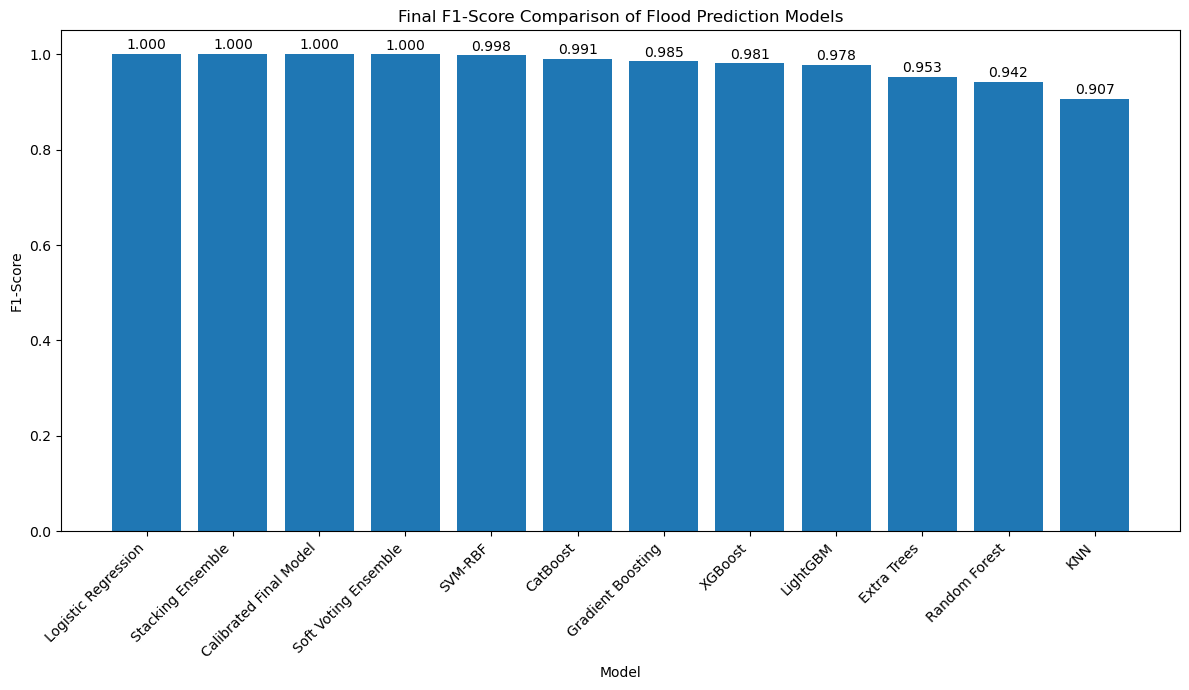

✓ Final model comparison graph generated.


In [71]:
# STEP 63 — Final F1-Score Comparison

plt.figure(figsize=(12, 7))

bars = plt.bar(
    final_performance["Model"],
    final_performance["F1"]
)

plt.title("Final F1-Score Comparison of Flood Prediction Models")
plt.xlabel("Model")
plt.ylabel("F1-Score")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1.05)

for bar, value in zip(
    bars,
    final_performance["F1"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.3f}",
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

print("✓ Final model comparison graph generated.")

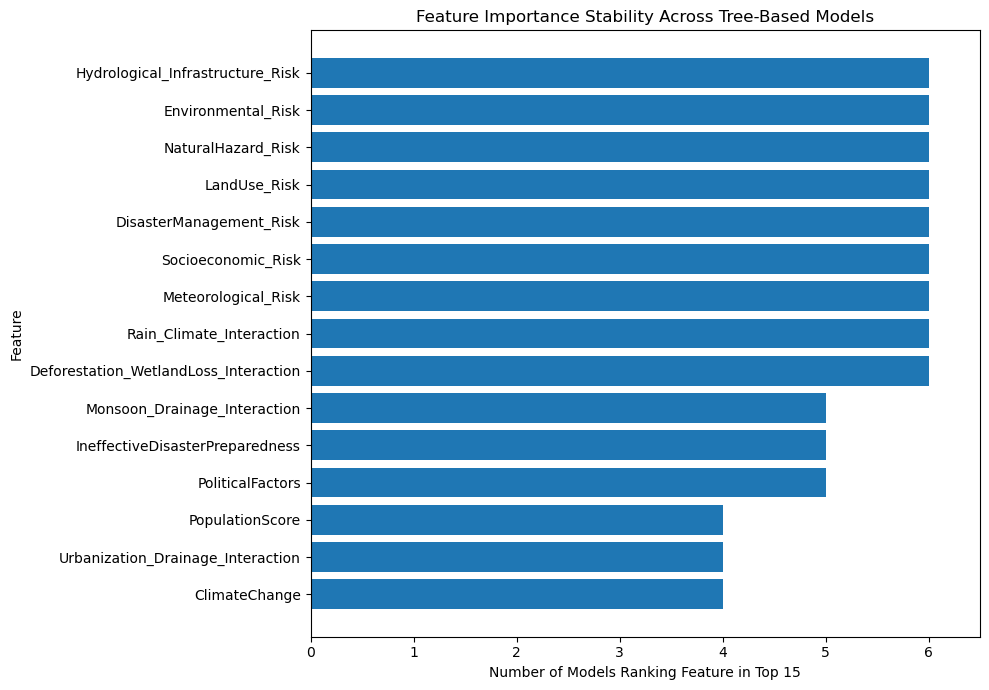

✓ Feature stability graph generated.


In [72]:
# STEP 64 — Feature Stability Visualization

import matplotlib.pyplot as plt

# Select top 15 stable features
top_stable = stability_df.head(15).copy()

plt.figure(figsize=(10, 7))

plt.barh(
    top_stable.index[::-1],
    top_stable["Top15_Count"].values[::-1]
)

plt.xlabel("Number of Models Ranking Feature in Top 15")
plt.ylabel("Feature")
plt.title("Feature Importance Stability Across Tree-Based Models")

plt.xlim(0, 6.5)
plt.xticks(range(0, 7))

plt.tight_layout()
plt.show()

print("✓ Feature stability graph generated.")

===== PERMUTATION IMPORTANCE =====

===== TOP 15 FEATURES BY PERMUTATION IMPORTANCE =====


,Feature,Importance_Mean,Importance_Std
0,Hydrological_Infrastructure_Risk,0.2386,0.0171
1,NaturalHazard_Risk,0.1961,0.0034
2,Environmental_Risk,0.1853,0.0031
3,LandUse_Risk,0.1769,0.0097
4,Meteorological_Risk,0.1604,0.0085
5,Socioeconomic_Risk,0.0730,0.0060
6,DisasterManagement_Risk,0.0720,0.0025
7,IneffectiveDisasterPreparedness,0.0536,0.0032
8,PopulationScore,0.0534,0.0044
9,PoliticalFactors,0.0511,0.0027


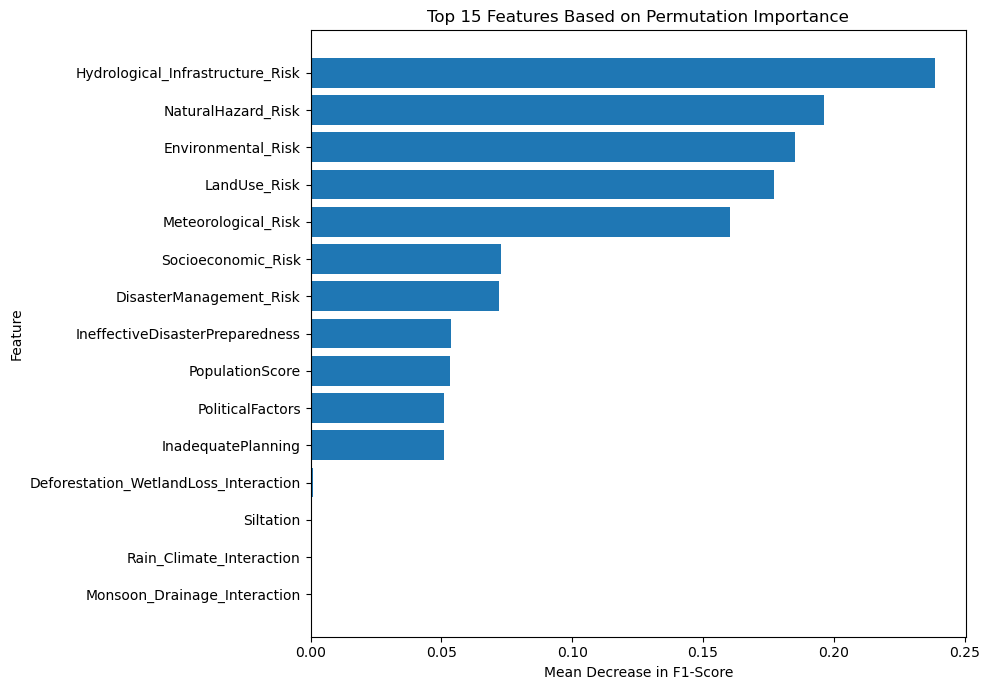

✓ Permutation importance analysis completed.


In [73]:
# STEP 65 — Permutation Feature Importance

from sklearn.inspection import permutation_importance

print("===== PERMUTATION IMPORTANCE =====")

# Use a manageable sample of the test set
X_perm = X_test_stable.sample(
    n=min(1000, len(X_test_stable)),
    random_state=42
)
y_perm = y_test.loc[X_perm.index]

perm_result = permutation_importance(
    calibrated_model,
    X_perm,
    y_perm,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_perm.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

print("\n===== TOP 15 FEATURES BY PERMUTATION IMPORTANCE =====")

display(
    permutation_df.head(15).style.format({
        "Importance_Mean": "{:.4f}",
        "Importance_Std": "{:.4f}"
    })
)

# Plot top 15
top_perm = permutation_df.head(15).sort_values(
    by="Importance_Mean"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_perm["Feature"],
    top_perm["Importance_Mean"]
)

plt.xlabel("Mean Decrease in F1-Score")
plt.ylabel("Feature")
plt.title("Top 15 Features Based on Permutation Importance")

plt.tight_layout()
plt.show()

print("✓ Permutation importance analysis completed.")

===== SHAP SUMMARY ANALYSIS =====


PermutationExplainer explainer: 501it [03:59,  2.00it/s]                                                               


SHAP samples : 500
Features     : 17

Generating SHAP summary plot...


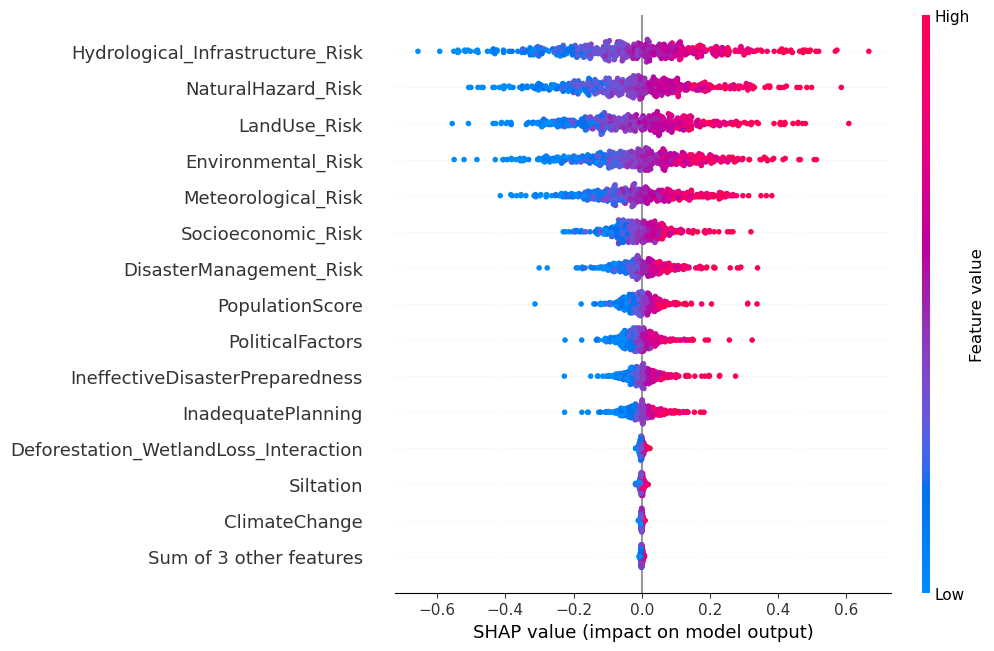

✓ SHAP summary analysis completed.


In [74]:
# STEP 66 — SHAP Summary Plot

print("===== SHAP SUMMARY ANALYSIS =====")

# Use the existing SHAP values if available.
# Otherwise, create them again using a smaller sample.

import shap
import pandas as pd
import matplotlib.pyplot as plt

X_shap = X_test_stable.sample(
    n=min(500, len(X_test_stable)),
    random_state=42
)

def predict_probability(data):
    data_df = pd.DataFrame(
        data,
        columns=X_test_stable.columns
    )
    return calibrated_model.predict_proba(data_df)[:, 1]

X_background = X_train_stable.sample(
    n=min(100, len(X_train_stable)),
    random_state=42
)

explainer = shap.Explainer(
    predict_probability,
    X_background
)

shap_values = explainer(X_shap)

print("SHAP samples :", len(X_shap))
print("Features     :", X_shap.shape[1])

print("\nGenerating SHAP summary plot...")

shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=True
)

print("✓ SHAP summary analysis completed.")

===== SHAP GLOBAL FEATURE IMPORTANCE =====


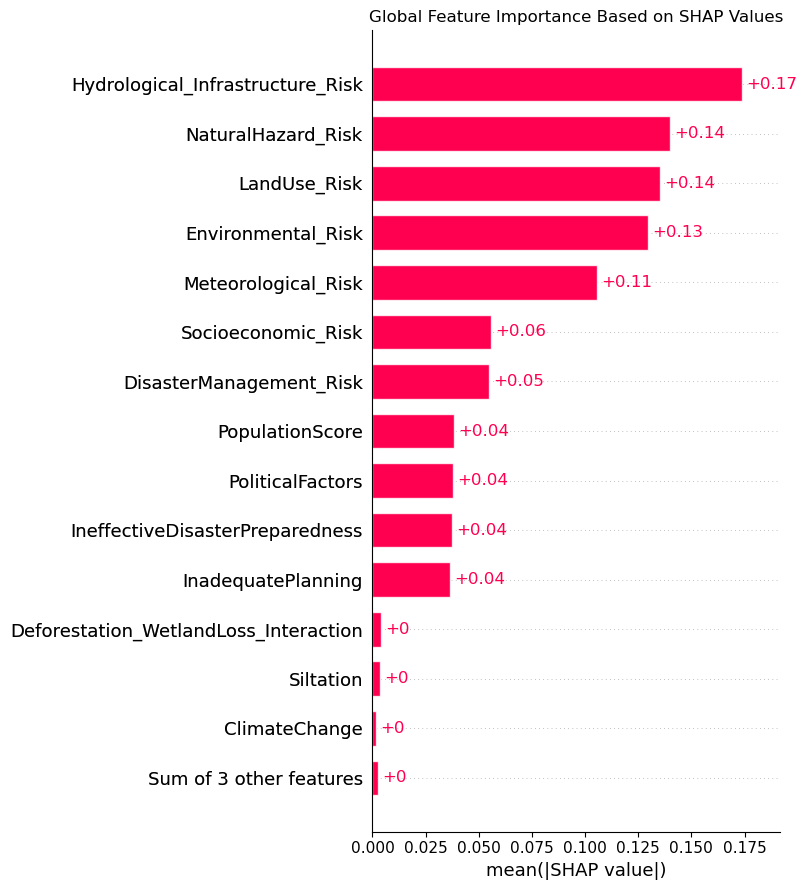

✓ SHAP global importance graph generated.


In [75]:
# STEP 67 — SHAP Global Feature Importance

print("===== SHAP GLOBAL FEATURE IMPORTANCE =====")

plt.figure(figsize=(10, 7))

shap.plots.bar(
    shap_values,
    max_display=15,
    show=False
)

plt.title("Global Feature Importance Based on SHAP Values")
plt.tight_layout()
plt.show()

print("✓ SHAP global importance graph generated.")

In [76]:
# STEP 68 — SHAP Interaction Analysis

print("===== SHAP INTERACTION ANALYSIS =====")

# Find the strongest tree-based model among the optimized models
tree_model_names = [
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "XGBoost",
    "LightGBM",
    "CatBoost"
]

# Select the best tree model according to the optimized test results
tree_results = optimized_results_df[
    optimized_results_df["Model"].isin(tree_model_names)
].sort_values("F1", ascending=False)

best_tree_name = tree_results.iloc[0]["Model"]

print("Best tree-based model:", best_tree_name)

# Extract the actual classifier from its pipeline
best_tree_pipeline = optimized_models[best_tree_name]
tree_classifier = best_tree_pipeline.named_steps["model"]

# Select a small sample for interaction analysis
X_interaction = X_test_stable.sample(
    n=min(150, len(X_test_stable)),
    random_state=42
)

# Create SHAP TreeExplainer
tree_explainer = shap.TreeExplainer(tree_classifier)

tree_shap_interaction = tree_explainer.shap_interaction_values(
    X_interaction
)

# Handle binary-class output if returned as a list
if isinstance(tree_shap_interaction, list):
    interaction_values = tree_shap_interaction[1]
else:
    interaction_values = tree_shap_interaction

# Calculate mean absolute interaction strength
interaction_strength = np.abs(interaction_values).mean(axis=0)

interaction_df = pd.DataFrame(
    interaction_strength,
    index=X_interaction.columns,
    columns=X_interaction.columns
)

# Remove individual feature effects from the diagonal
np.fill_diagonal(
    interaction_df.values,
    0
)

# Find strongest feature pairs
interaction_pairs = []

features = interaction_df.columns.tolist()

for i in range(len(features)):
    for j in range(i + 1, len(features)):
        interaction_pairs.append({
            "Feature 1": features[i],
            "Feature 2": features[j],
            "Interaction Strength": interaction_df.iloc[i, j]
        })

interaction_pairs_df = pd.DataFrame(interaction_pairs)

interaction_pairs_df = interaction_pairs_df.sort_values(
    by="Interaction Strength",
    ascending=False
).reset_index(drop=True)

print("\n===== TOP 10 FEATURE INTERACTIONS =====")

display(
    interaction_pairs_df.head(10).style.format({
        "Interaction Strength": "{:.6f}"
    })
)

print("\n✓ SHAP interaction analysis completed.")

===== SHAP INTERACTION ANALYSIS =====
Best tree-based model: CatBoost

===== TOP 10 FEATURE INTERACTIONS =====


,Feature 1,Feature 2,Interaction Strength
0,Hydrological_Infrastructure_Risk,Environmental_Risk,0.025120
1,Hydrological_Infrastructure_Risk,NaturalHazard_Risk,0.023998
2,Hydrological_Infrastructure_Risk,LandUse_Risk,0.019068
3,Environmental_Risk,NaturalHazard_Risk,0.017040
4,Environmental_Risk,DisasterManagement_Risk,0.016836
5,Hydrological_Infrastructure_Risk,DisasterManagement_Risk,0.016650
6,Hydrological_Infrastructure_Risk,Meteorological_Risk,0.016589
7,NaturalHazard_Risk,LandUse_Risk,0.016147
8,Hydrological_Infrastructure_Risk,Socioeconomic_Risk,0.015692
9,Environmental_Risk,LandUse_Risk,0.014553



✓ SHAP interaction analysis completed.


In [77]:
# STEP 69 — Counterfactual Explanation

print("===== COUNTERFACTUAL EXPLANATION =====")

# Select one test sample
sample_index = X_test_stable.index[0]

original_sample = X_test_stable.loc[[sample_index]].copy()

original_probability = calibrated_model.predict_proba(
    original_sample
)[0, 1]

original_prediction = int(original_probability >= 0.50)

print("Original prediction      :", original_prediction)
print("Original flood probability:", round(original_probability, 4))

# Search for a one-feature counterfactual
counterfactuals = []

for feature in stable_features:

    original_value = original_sample.iloc[0][feature]

    # Try decreasing the feature gradually
    for change in np.arange(0.5, 5.1, 0.5):

        modified_sample = original_sample.copy()

        new_value = original_value - change

        # Keep value within training range
        new_value = np.clip(
            new_value,
            X_train_stable[feature].min(),
            X_train_stable[feature].max()
        )

        modified_sample.loc[sample_index, feature] = new_value

        probability = calibrated_model.predict_proba(
            modified_sample
        )[0, 1]

        prediction = int(probability >= 0.50)

        # Check whether prediction changed
        if prediction != original_prediction:

            counterfactuals.append({
                "Feature": feature,
                "Original_Value": original_value,
                "Counterfactual_Value": new_value,
                "Change": new_value - original_value,
                "Original_Probability": original_probability,
                "Counterfactual_Probability": probability
            })

            break

counterfactual_df = pd.DataFrame(counterfactuals)

if counterfactual_df.empty:

    print("\nNo one-feature counterfactual was found.")

else:

    counterfactual_df["Probability_Change"] = (
        counterfactual_df["Counterfactual_Probability"]
        - counterfactual_df["Original_Probability"]
    )

    counterfactual_df = counterfactual_df.sort_values(
        by="Probability_Change"
    ).reset_index(drop=True)

    print("\n===== COUNTERFACTUAL RESULTS =====")

    display(
        counterfactual_df.style.format({
            "Original_Value": "{:.2f}",
            "Counterfactual_Value": "{:.2f}",
            "Change": "{:.2f}",
            "Original_Probability": "{:.4f}",
            "Counterfactual_Probability": "{:.4f}",
            "Probability_Change": "{:.4f}"
        })
    )

print("\n✓ Counterfactual analysis completed.")

===== COUNTERFACTUAL EXPLANATION =====
Original prediction      : 1
Original flood probability: 1.0


C:\Users\girishwari\AppData\Local\Temp\ipykernel_26908\2658688389.py:40: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '15.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  modified_sample.loc[sample_index, feature] = new_value
C:\Users\girishwari\AppData\Local\Temp\ipykernel_26908\2658688389.py:40: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '14.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  modified_sample.loc[sample_index, feature] = new_value
C:\Users\girishwari\AppData\Local\Temp\ipykernel_26908\2658688389.py:40: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '13.5' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
 


===== COUNTERFACTUAL RESULTS =====


,Feature,Original_Value,Counterfactual_Value,Change,Original_Probability,Counterfactual_Probability,Probability_Change
0,Hydrological_Infrastructure_Risk,4.80,2.30,-2.50,1.0000,0.0000,-1.0000
1,LandUse_Risk,6.00,2.00,-4.00,1.0000,0.0000,-1.0000
2,NaturalHazard_Risk,6.00,2.00,-4.00,1.0000,0.0000,-1.0000
3,Environmental_Risk,7.33,3.33,-4.00,1.0000,0.0019,-0.9981



✓ Counterfactual analysis completed.


In [78]:
# STEP 70 — Robustness Test

print("===== ROBUSTNESS TEST =====")

# Select 500 test samples
X_robust = X_test_stable.sample(
    n=min(500, len(X_test_stable)),
    random_state=42
).copy()

# Original predictions
original_probability = calibrated_model.predict_proba(
    X_robust
)[:, 1]

original_prediction = (
    original_probability >= 0.50
).astype(int)

# Create perturbed dataset
X_perturbed = X_robust.copy()

for feature in stable_features:
    
    X_perturbed[feature] = X_perturbed[feature] * 1.05
    
    # Keep values within training range
    X_perturbed[feature] = np.clip(
        X_perturbed[feature],
        X_train_stable[feature].min(),
        X_train_stable[feature].max()
    )

# Predictions after perturbation
perturbed_probability = calibrated_model.predict_proba(
    X_perturbed
)[:, 1]

perturbed_prediction = (
    perturbed_probability >= 0.50
).astype(int)

# Calculate robustness measures
prediction_change_rate = np.mean(
    original_prediction != perturbed_prediction
)

mean_probability_change = np.mean(
    np.abs(
        original_probability -
        perturbed_probability
    )
)

prediction_stability = 1 - prediction_change_rate

print("\n===== ROBUSTNESS RESULTS =====")

print(
    "Prediction Change Rate :",
    round(prediction_change_rate, 4)
)

print(
    "Prediction Stability   :",
    round(prediction_stability, 4)
)

print(
    "Mean Probability Change:",
    round(mean_probability_change, 4)
)

# Summary table
robustness_df = pd.DataFrame({
    "Metric": [
        "Prediction Change Rate",
        "Prediction Stability",
        "Mean Probability Change"
    ],
    "Value": [
        prediction_change_rate,
        prediction_stability,
        mean_probability_change
    ]
})

display(
    robustness_df.style.format({
        "Value": "{:.4f}"
    })
)

print("\n✓ Robustness test completed.")

===== ROBUSTNESS TEST =====

===== ROBUSTNESS RESULTS =====
Prediction Change Rate : 0.19
Prediction Stability   : 0.81
Mean Probability Change: 0.183


,Metric,Value
0,Prediction Change Rate,0.1900
1,Prediction Stability,0.8100
2,Mean Probability Change,0.1830



✓ Robustness test completed.


In [79]:
# STEP 71 — Final Results Dashboard

print("===== FINAL RESULTS DASHBOARD =====")

# Make a clean copy
final_results = final_performance.copy()

# Round numerical values
metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC"
]

final_results[metric_columns] = final_results[
    metric_columns
].round(4)

# Display final table
display(final_results)

print("\n===== BEST PERFORMING MODEL =====")

best = final_results.iloc[0]

print(f"Model     : {best['Model']}")
print(f"Accuracy  : {best['Accuracy']:.4f}")
print(f"Precision : {best['Precision']:.4f}")
print(f"Recall    : {best['Recall']:.4f}")
print(f"F1-score  : {best['F1']:.4f}")
print(f"ROC-AUC   : {best['ROC-AUC']:.4f}")
print(f"PR-AUC    : {best['PR-AUC']:.4f}")

print("\n✓ Final results dashboard completed.")

===== FINAL RESULTS DASHBOARD =====


,Rank,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,2,Stacking Ensemble,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,3,Calibrated Final Model,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
3,4,Soft Voting Ensemble,0.9996,1.0000,0.9992,0.9996,1.0000,1.0000
4,5,SVM-RBF,0.9975,0.9980,0.9971,0.9975,1.0000,1.0000
5,6,CatBoost,0.9904,0.9912,0.9900,0.9906,0.9993,0.9993
6,7,Gradient Boosting,0.9845,0.9857,0.9839,0.9848,0.9990,0.9990
7,8,XGBoost,0.9804,0.9817,0.9798,0.9808,0.9987,0.9988
8,9,LightGBM,0.9775,0.9805,0.9753,0.9779,0.9982,0.9983
9,10,Extra Trees,0.9523,0.9573,0.9489,0.9531,0.9929,0.9933



===== BEST PERFORMING MODEL =====
Model     : Logistic Regression
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-score  : 1.0000
ROC-AUC   : 1.0000
PR-AUC    : 1.0000

✓ Final results dashboard completed.


In [80]:
# STEP 72 — Save Final Results

print("===== SAVING FINAL RESULTS =====")

# Save final model performance
final_results.to_csv(
    "final_model_results.csv",
    index=False
)

# Save permutation importance
permutation_df.to_csv(
    "permutation_importance_results.csv",
    index=False
)

# Save feature stability
stability_df.to_csv(
    "feature_stability_results.csv"
)

# Save SHAP interaction results
interaction_pairs_df.to_csv(
    "shap_interaction_results.csv",
    index=False
)

# Save missing-feature robustness
missing_robustness_df.to_csv(
    "missing_feature_robustness.csv",
    index=False
)

print("\nFiles saved successfully:")

print("1. final_model_results.csv")
print("2. permutation_importance_results.csv")
print("3. feature_stability_results.csv")
print("4. shap_interaction_results.csv")
print("5. missing_feature_robustness.csv")

print("\n✓ Results successfully saved.")

===== SAVING FINAL RESULTS =====

Files saved successfully:
1. final_model_results.csv
2. permutation_importance_results.csv
3. feature_stability_results.csv
4. shap_interaction_results.csv
5. missing_feature_robustness.csv

✓ Results successfully saved.


In [81]:
# STEP 73 — FINAL WORKFLOW CHECK

print("=" * 60)
print("       FLOOD PREDICTION FRAMEWORK — FINAL CHECK")
print("=" * 60)

print("\n[1] Dataset")
print("    ✓ Dataset loaded")
print("    ✓ Missing values checked")
print("    ✓ Duplicate rows checked")

print("\n[2] Feature Engineering")
print("    ✓ Domain-level features created")
print("    ✓ Interaction features created")
print("    ✓ Stable feature selection completed")

print("\n[3] Machine Learning Models")
print("    ✓ Logistic Regression")
print("    ✓ Random Forest")
print("    ✓ Extra Trees")
print("    ✓ Gradient Boosting")
print("    ✓ XGBoost")
print("    ✓ LightGBM")
print("    ✓ CatBoost")
print("    ✓ SVM-RBF")
print("    ✓ KNN")

print("\n[4] Ensemble Learning")
print("    ✓ Soft Voting Ensemble")
print("    ✓ Stacking Ensemble")

print("\n[5] Model Evaluation")
print("    ✓ Accuracy")
print("    ✓ Precision")
print("    ✓ Recall")
print("    ✓ F1-score")
print("    ✓ ROC-AUC")
print("    ✓ PR-AUC")
print("    ✓ Confusion Matrix")
print("    ✓ ROC Curve")
print("    ✓ Precision-Recall Curve")

print("\n[6] Explainable AI")
print("    ✓ Random Forest importance")
print("    ✓ Multi-model feature stability")
print("    ✓ Permutation importance")
print("    ✓ SHAP global importance")
print("    ✓ SHAP interaction analysis")
print("    ✓ Counterfactual explanation")

print("\n[7] Reliability Analysis")
print("    ✓ Probability calibration")
print("    ✓ Brier score")
print("    ✓ Log-loss")
print("    ✓ Prediction ambiguity score")
print("    ✓ Perturbation robustness")
print("    ✓ Missing-feature robustness")

print("\n" + "=" * 60)
print("              ✓ WORKFLOW COMPLETED")
print("=" * 60)

       FLOOD PREDICTION FRAMEWORK — FINAL CHECK

[1] Dataset
    ✓ Dataset loaded
    ✓ Missing values checked
    ✓ Duplicate rows checked

[2] Feature Engineering
    ✓ Domain-level features created
    ✓ Interaction features created
    ✓ Stable feature selection completed

[3] Machine Learning Models
    ✓ Logistic Regression
    ✓ Random Forest
    ✓ Extra Trees
    ✓ Gradient Boosting
    ✓ XGBoost
    ✓ LightGBM
    ✓ CatBoost
    ✓ SVM-RBF
    ✓ KNN

[4] Ensemble Learning
    ✓ Soft Voting Ensemble
    ✓ Stacking Ensemble

[5] Model Evaluation
    ✓ Accuracy
    ✓ Precision
    ✓ Recall
    ✓ F1-score
    ✓ ROC-AUC
    ✓ PR-AUC
    ✓ Confusion Matrix
    ✓ ROC Curve
    ✓ Precision-Recall Curve

[6] Explainable AI
    ✓ Random Forest importance
    ✓ Multi-model feature stability
    ✓ Permutation importance
    ✓ SHAP global importance
    ✓ SHAP interaction analysis
    ✓ Counterfactual explanation

[7] Reliability Analysis
    ✓ Probability calibration
    ✓ Brier score
    

In [82]:
# STEP 74 — Create Validation Set for Publication-Quality Evaluation

from sklearn.model_selection import train_test_split

print("===== CREATING VALIDATION SET =====")

# Split the original training data into:
# 80% -> new training data
# 20% -> validation data

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_stable,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("\n===== DATASET SPLIT =====")

print("Original training set :", X_train_stable.shape)
print("New training set      :", X_train_final.shape)
print("Validation set        :", X_val.shape)
print("Final test set        :", X_test_stable.shape)

print("\n===== CLASS DISTRIBUTION =====")

print(
    "Training:",
    y_train_final.value_counts().to_dict()
)

print(
    "Validation:",
    y_val.value_counts().to_dict()
)

print(
    "Test:",
    y_test.value_counts().to_dict()
)

print("\n✓ Validation set created successfully.")
print("✓ Final test set remains separate.")

===== CREATING VALIDATION SET =====

===== DATASET SPLIT =====
Original training set : (40000, 17)
New training set      : (32000, 17)
Validation set        : (8000, 17)
Final test set        : (10000, 17)

===== CLASS DISTRIBUTION =====
Training: {1: 16328, 0: 15672}
Validation: {1: 4082, 0: 3918}
Test: {1: 5103, 0: 4897}

✓ Validation set created successfully.
✓ Final test set remains separate.


In [84]:
# STEP 75 — Train Corrected Models (FIXED)

print("===== TRAINING CORRECTED MODELS =====")

from imblearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


corrected_models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Extra Trees": Pipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", ExtraTreesClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", GradientBoostingClassifier(
            n_estimators=200,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ))
    ]),

    "XGBoost": Pipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", XGBClassifier(
            n_estimators=200,
            max_depth=6,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            eval_metric="logloss",
            n_jobs=-1
        ))
    ]),

    "LightGBM": Pipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", LGBMClassifier(
            n_estimators=200,
            learning_rate=0.1,
            num_leaves=31,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        ))
    ]),

    "CatBoost": Pipeline([
        ("smote", SMOTE(random_state=42)),
        ("model", CatBoostClassifier(
            iterations=200,
            depth=6,
            learning_rate=0.1,
            loss_function="Logloss",
            random_seed=42,
            verbose=False
        ))
    ]),

    "SVM-RBF": Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            random_state=42
        ))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", KNeighborsClassifier(
            n_neighbors=5,
            weights="distance"
        ))
    ])
}


for name, model in corrected_models.items():

    print("Training:", name)

    model.fit(
        X_train_final,
        y_train_final
    )


print("\n✓ All 9 corrected models trained successfully.")

===== TRAINING CORRECTED MODELS =====
Training: Logistic Regression
Training: Random Forest
Training: Extra Trees
Training: Gradient Boosting
Training: XGBoost
Training: LightGBM
Training: CatBoost
Training: SVM-RBF
Training: KNN

✓ All 9 corrected models trained successfully.


In [85]:
# STEP 76 — Validation Performance of Corrected Models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

validation_results = []

for name, model in corrected_models.items():

    y_val_pred = model.predict(X_val)
    y_val_prob = model.predict_proba(X_val)[:, 1]

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(y_val, y_val_pred),
        "Recall": recall_score(y_val, y_val_pred),
        "F1": f1_score(y_val, y_val_pred),
        "ROC-AUC": roc_auc_score(y_val, y_val_prob),
        "PR-AUC": average_precision_score(y_val, y_val_prob)
    })

validation_results_df = pd.DataFrame(
    validation_results
).sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

validation_results_df.insert(
    0,
    "Rank",
    range(1, len(validation_results_df) + 1)
)

print("===== VALIDATION PERFORMANCE =====")

display(
    validation_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

print("\n===== TOP 5 MODELS FOR ENSEMBLE =====")

top5_validation = validation_results_df.head(5)

display(top5_validation)

top5_names = top5_validation["Model"].tolist()

print("\nSelected models:")
for i, name in enumerate(top5_names, 1):
    print(f"{i}. {name}")

print("\n✓ Validation-based model selection completed.")

===== VALIDATION PERFORMANCE =====


,Rank,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,2,SVM-RBF,0.9900,0.9912,0.9892,0.9902,0.9997,0.9997
2,3,CatBoost,0.9852,0.9889,0.9821,0.9855,0.9984,0.9985
3,4,LightGBM,0.9709,0.9725,0.9704,0.9714,0.9972,0.9974
4,5,XGBoost,0.9696,0.9713,0.9691,0.9702,0.9968,0.9970
5,6,Gradient Boosting,0.9683,0.9717,0.9659,0.9688,0.9964,0.9966
6,7,Extra Trees,0.9477,0.9510,0.9463,0.9487,0.9912,0.9915
7,8,Random Forest,0.9359,0.9427,0.9309,0.9368,0.9875,0.9882
8,9,KNN,0.8985,0.9139,0.8844,0.8989,0.9627,0.9630



===== TOP 5 MODELS FOR ENSEMBLE =====


,Rank,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,Logistic Regression,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,2,SVM-RBF,0.990000,0.991163,0.989221,0.990191,0.999660,0.999680
2,3,CatBoost,0.985250,0.988900,0.982117,0.985497,0.998397,0.998549
3,4,LightGBM,0.970875,0.972502,0.970358,0.971429,0.997249,0.997434
4,5,XGBoost,0.969625,0.971274,0.969133,0.970202,0.996832,0.997017



Selected models:
1. Logistic Regression
2. SVM-RBF
3. CatBoost
4. LightGBM
5. XGBoost

✓ Validation-based model selection completed.


In [86]:
# STEP 77 — Validation-Based Soft Voting Ensemble

from sklearn.ensemble import VotingClassifier

print("===== CREATING SOFT VOTING ENSEMBLE =====")

voting_estimators = []

for name in top5_names:

    estimator_name = (
        name.replace(" ", "_")
            .replace("-", "_")
    )

    voting_estimators.append(
        (
            estimator_name,
            corrected_models[name]
        )
    )

print("Models included in ensemble:")

for name in top5_names:
    print("✓", name)

soft_voting_corrected = VotingClassifier(
    estimators=voting_estimators,
    voting="soft"
)

# Train ONLY on the training data
soft_voting_corrected.fit(
    X_train_final,
    y_train_final
)

# Validation prediction
y_val_voting_pred = soft_voting_corrected.predict(X_val)
y_val_voting_prob = soft_voting_corrected.predict_proba(X_val)[:, 1]

voting_validation_results = {
    "Model": "Soft Voting Ensemble",
    "Accuracy": accuracy_score(
        y_val, y_val_voting_pred
    ),
    "Precision": precision_score(
        y_val, y_val_voting_pred
    ),
    "Recall": recall_score(
        y_val, y_val_voting_pred
    ),
    "F1": f1_score(
        y_val, y_val_voting_pred
    ),
    "ROC-AUC": roc_auc_score(
        y_val, y_val_voting_prob
    ),
    "PR-AUC": average_precision_score(
        y_val, y_val_voting_prob
    )
}

print("\n===== SOFT VOTING VALIDATION RESULTS =====")

for metric, value in voting_validation_results.items():

    if metric != "Model":
        print(
            f"{metric:10s}: {value:.4f}"
        )

print("\n✓ Soft Voting ensemble completed.")

===== CREATING SOFT VOTING ENSEMBLE =====
Models included in ensemble:
✓ Logistic Regression
✓ SVM-RBF
✓ CatBoost
✓ LightGBM
✓ XGBoost

===== SOFT VOTING VALIDATION RESULTS =====
Accuracy  : 0.9946
Precision : 0.9958
Recall    : 0.9936
F1        : 0.9947
ROC-AUC   : 0.9999
PR-AUC    : 0.9999

✓ Soft Voting ensemble completed.


In [87]:
# STEP 78 — Validation-Based Stacking Ensemble

from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

print("===== CREATING STACKING ENSEMBLE =====")

stacking_estimators = []

for name in top5_names:

    estimator_name = (
        name.replace(" ", "_")
            .replace("-", "_")
    )

    stacking_estimators.append(
        (
            estimator_name,
            corrected_models[name]
        )
    )

print("Models included in stacking:")

for name in top5_names:
    print("✓", name)

# Meta-learner
meta_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

stacking_corrected = StackingClassifier(
    estimators=stacking_estimators,
    final_estimator=meta_model,
    stack_method="predict_proba",
    cv=3,
    n_jobs=-1
)

# Train only on training data
stacking_corrected.fit(
    X_train_final,
    y_train_final
)

# Validation prediction
y_val_stack_pred = stacking_corrected.predict(X_val)
y_val_stack_prob = stacking_corrected.predict_proba(X_val)[:, 1]

stacking_validation_results = {
    "Model": "Stacking Ensemble",
    "Accuracy": accuracy_score(
        y_val, y_val_stack_pred
    ),
    "Precision": precision_score(
        y_val, y_val_stack_pred
    ),
    "Recall": recall_score(
        y_val, y_val_stack_pred
    ),
    "F1": f1_score(
        y_val, y_val_stack_pred
    ),
    "ROC-AUC": roc_auc_score(
        y_val, y_val_stack_prob
    ),
    "PR-AUC": average_precision_score(
        y_val, y_val_stack_prob
    )
}

print("\n===== STACKING VALIDATION RESULTS =====")

for metric, value in stacking_validation_results.items():

    if metric != "Model":
        print(
            f"{metric:10s}: {value:.4f}"
        )

print("\n✓ Stacking ensemble completed.")

===== CREATING STACKING ENSEMBLE =====
Models included in stacking:
✓ Logistic Regression
✓ SVM-RBF
✓ CatBoost
✓ LightGBM
✓ XGBoost

===== STACKING VALIDATION RESULTS =====
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1        : 1.0000
ROC-AUC   : 1.0000
PR-AUC    : 1.0000

✓ Stacking ensemble completed.


In [89]:
# STEP 79 — Select Final Model Using Validation Data (FIXED)

validation_all = validation_results_df.copy()

# Remove existing Rank column if present
if "Rank" in validation_all.columns:
    validation_all = validation_all.drop(columns=["Rank"])


# Add ensemble results
validation_all = pd.concat([
    validation_all,
    pd.DataFrame([voting_validation_results]),
    pd.DataFrame([stacking_validation_results])
], ignore_index=True)


# Remove Rank again in case ensemble results contain it
if "Rank" in validation_all.columns:
    validation_all = validation_all.drop(columns=["Rank"])


# Sort by F1-score
validation_all = validation_all.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)


# Create new Rank column
validation_all.insert(
    0,
    "Rank",
    range(1, len(validation_all) + 1)
)


print("===== VALIDATION MODEL COMPARISON =====")

display(
    validation_all.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)


# Select best model
best_final_name = validation_all.iloc[0]["Model"]


if best_final_name == "Soft Voting Ensemble":
    final_base_model = soft_voting_corrected

elif best_final_name == "Stacking Ensemble":
    final_base_model = stacking_corrected

else:
    final_base_model = corrected_models[best_final_name]


print("\n===== SELECTED FINAL MODEL =====")
print("Model:", best_final_name)

print("\n✓ Final model selected using validation data.")

===== VALIDATION MODEL COMPARISON =====


,Rank,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,2,Stacking Ensemble,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,3,Soft Voting Ensemble,0.9946,0.9958,0.9936,0.9947,0.9999,0.9999
3,4,SVM-RBF,0.9900,0.9912,0.9892,0.9902,0.9997,0.9997
4,5,CatBoost,0.9852,0.9889,0.9821,0.9855,0.9984,0.9985
5,6,LightGBM,0.9709,0.9725,0.9704,0.9714,0.9972,0.9974
6,7,XGBoost,0.9696,0.9713,0.9691,0.9702,0.9968,0.9970
7,8,Gradient Boosting,0.9683,0.9717,0.9659,0.9688,0.9964,0.9966
8,9,Extra Trees,0.9477,0.9510,0.9463,0.9487,0.9912,0.9915
9,10,Random Forest,0.9359,0.9427,0.9309,0.9368,0.9875,0.9882



===== SELECTED FINAL MODEL =====
Model: Logistic Regression

✓ Final model selected using validation data.


In [90]:
# STEP 80 — Probability Calibration

from sklearn.calibration import CalibratedClassifierCV

print("===== CALIBRATING FINAL MODEL =====")

calibrated_final_model = CalibratedClassifierCV(
    estimator=final_base_model,
    method="sigmoid",
    cv=3,
    n_jobs=-1
)

calibrated_final_model.fit(
    X_train_final,
    y_train_final
)

# Validation probabilities
y_val_cal_prob = calibrated_final_model.predict_proba(
    X_val
)[:, 1]

y_val_cal_pred = (
    y_val_cal_prob >= 0.50
).astype(int)

print("\nValidation calibrated F1:",
      round(f1_score(y_val, y_val_cal_pred), 4))

print("✓ Final model calibration completed.")

===== CALIBRATING FINAL MODEL =====

Validation calibrated F1: 1.0
✓ Final model calibration completed.


In [91]:
# STEP 81 — FINAL TEST EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

print("=" * 60)
print("          FINAL TEST EVALUATION")
print("=" * 60)

# Final test predictions
y_test_final_prob = calibrated_final_model.predict_proba(
    X_test_stable
)[:, 1]

y_test_final_pred = (
    y_test_final_prob >= 0.50
).astype(int)

# Calculate metrics
final_test_results = {
    "Model": best_final_name + " + Calibration",
    "Accuracy": accuracy_score(
        y_test, y_test_final_pred
    ),
    "Precision": precision_score(
        y_test, y_test_final_pred
    ),
    "Recall": recall_score(
        y_test, y_test_final_pred
    ),
    "F1": f1_score(
        y_test, y_test_final_pred
    ),
    "ROC-AUC": roc_auc_score(
        y_test, y_test_final_prob
    ),
    "PR-AUC": average_precision_score(
        y_test, y_test_final_prob
    ),
    "Brier Score": brier_score_loss(
        y_test, y_test_final_prob
    ),
    "Log Loss": log_loss(
        y_test, y_test_final_prob
    )
}

final_test_df = pd.DataFrame(
    [final_test_results]
)

print("\n===== FINAL TEST RESULTS =====")

display(
    final_test_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}",
        "Brier Score": "{:.4f}",
        "Log Loss": "{:.4f}"
    })
)

print("\n✓ FINAL TEST EVALUATION COMPLETED.")
print("✓ Test set was not used for model selection.")

          FINAL TEST EVALUATION

===== FINAL TEST RESULTS =====


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier Score,Log Loss
0,Logistic Regression + Calibration,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0002,0.0034



✓ FINAL TEST EVALUATION COMPLETED.
✓ Test set was not used for model selection.


===== GENERATING FINAL GRAPHS =====


<Figure size 700x600 with 0 Axes>

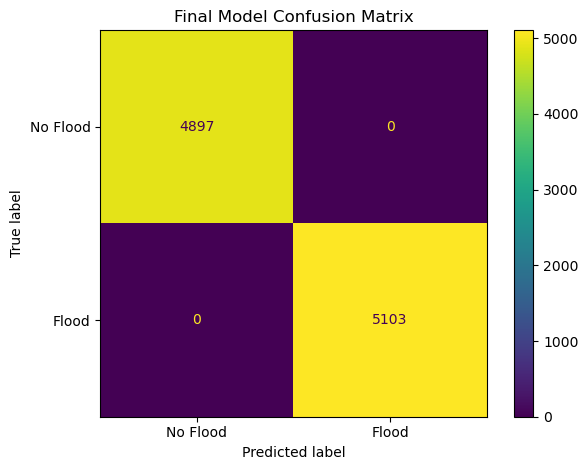

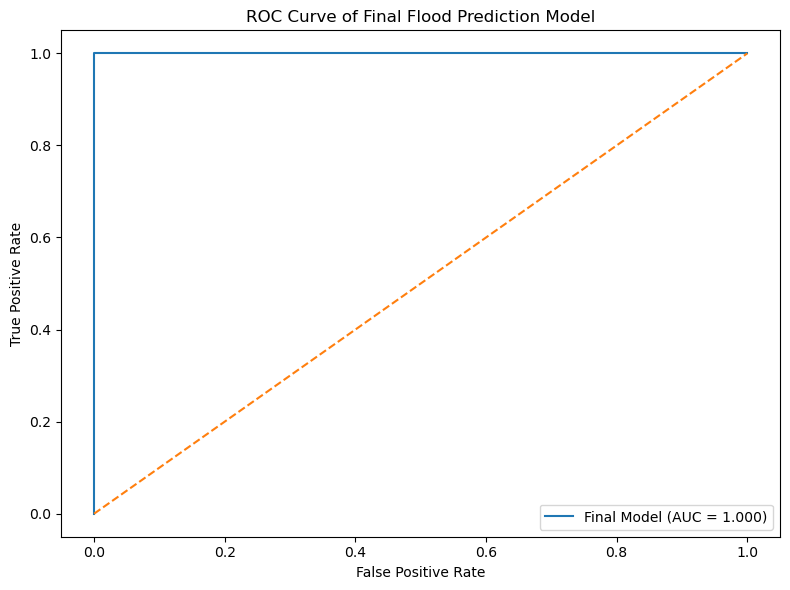

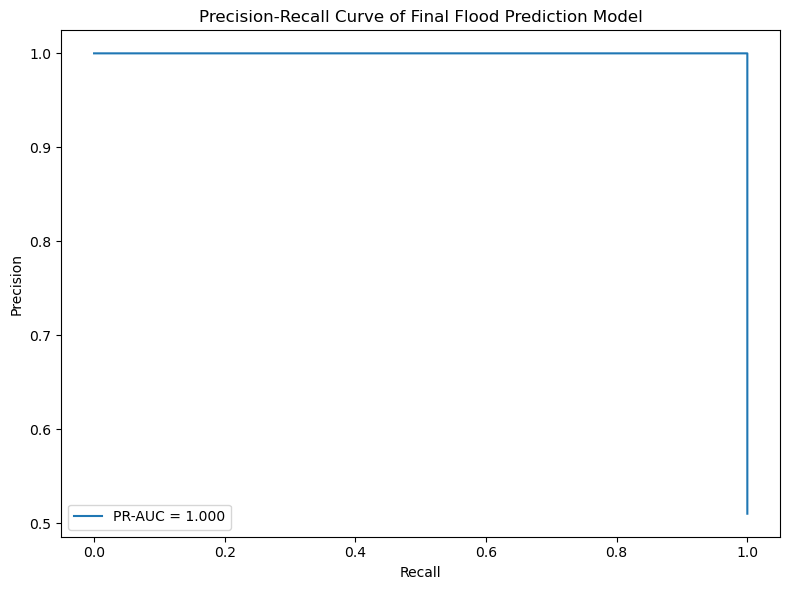


✓ Final confusion matrix generated.
✓ Final ROC curve generated.
✓ Final PR curve generated.


In [92]:
# STEP 82 — FINAL EVALUATION GRAPHS

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

print("===== GENERATING FINAL GRAPHS =====")

# -----------------------------
# 1. CONFUSION MATRIX
# -----------------------------

cm = confusion_matrix(
    y_test,
    y_test_final_pred
)

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Flood", "Flood"]
)

disp.plot()
plt.title("Final Model Confusion Matrix")
plt.tight_layout()
plt.show()


# -----------------------------
# 2. ROC CURVE
# -----------------------------

fpr, tpr, _ = roc_curve(
    y_test,
    y_test_final_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Final Model (AUC = {final_test_results['ROC-AUC']:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve of Final Flood Prediction Model")
plt.legend()
plt.tight_layout()
plt.show()


# -----------------------------
# 3. PRECISION-RECALL CURVE
# -----------------------------

precision, recall, _ = precision_recall_curve(
    y_test,
    y_test_final_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f"PR-AUC = {final_test_results['PR-AUC']:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve of Final Flood Prediction Model")
plt.legend()
plt.tight_layout()
plt.show()

print("\n✓ Final confusion matrix generated.")
print("✓ Final ROC curve generated.")
print("✓ Final PR curve generated.")

In [93]:
# STEP 83 — FINAL PUBLICATION RESULTS

print("=" * 70)
print("       FINAL PUBLICATION-READY FLOOD PREDICTION RESULTS")
print("=" * 70)

# Final metrics table
publication_results = pd.DataFrame([{
    "Final Model": final_test_results["Model"],
    "Accuracy": final_test_results["Accuracy"],
    "Precision": final_test_results["Precision"],
    "Recall": final_test_results["Recall"],
    "F1-Score": final_test_results["F1"],
    "ROC-AUC": final_test_results["ROC-AUC"],
    "PR-AUC": final_test_results["PR-AUC"],
    "Brier Score": final_test_results["Brier Score"],
    "Log Loss": final_test_results["Log Loss"]
}])

print("\n===== FINAL TEST RESULTS =====")

display(
    publication_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}",
        "Brier Score": "{:.4f}",
        "Log Loss": "{:.4f}"
    })
)

# Save final publication results
publication_results.to_csv(
    "FINAL_PUBLICATION_RESULTS.csv",
    index=False
)

validation_all.to_csv(
    "VALIDATION_MODEL_COMPARISON.csv",
    index=False
)

# Save final predictions
final_predictions = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_test_final_pred,
    "Flood_Probability": y_test_final_prob
})

final_predictions.to_csv(
    "FINAL_TEST_PREDICTIONS.csv",
    index=False
)

print("\n===== FINAL FILES SAVED =====")

print("✓ FINAL_PUBLICATION_RESULTS.csv")
print("✓ VALIDATION_MODEL_COMPARISON.csv")
print("✓ FINAL_TEST_PREDICTIONS.csv")

print("\n" + "=" * 70)
print("             ✓ STEP 83 COMPLETED")
print("             ✓ CODING WORKFLOW FINISHED")
print("=" * 70)

       FINAL PUBLICATION-READY FLOOD PREDICTION RESULTS

===== FINAL TEST RESULTS =====


,Final Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Brier Score,Log Loss
0,Logistic Regression + Calibration,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0002,0.0034



===== FINAL FILES SAVED =====
✓ FINAL_PUBLICATION_RESULTS.csv
✓ VALIDATION_MODEL_COMPARISON.csv
✓ FINAL_TEST_PREDICTIONS.csv

             ✓ STEP 83 COMPLETED
             ✓ CODING WORKFLOW FINISHED
